# 🍽️ Concierge · CRISP-DM | 03a · Data Preparation e Modeling com o Yelp real

**Grupo:** Fabrício Wenter, Gabriel Gandolfi, Luís Gustavo Barbosa e Murilo Pilão

**Bases usadas (Yelp Open Dataset):** `business`, `tip` e `checkin`. O recorte é Philadelphia + categoria *Restaurants*,
como definido no BU.

**O que muda em relação à versão anterior:** sem `review.json` não existe a nota que **cada usuário** deu a **cada
restaurante**. Por isso a preferência do consumidor é modelada em duas partes, com o que as três bases oferecem:

| Modelo | Pergunta | Alvo | Fonte do alvo |
|---|---|---|---|
| **A · Aprovação** | os consumidores aprovam este restaurante? | `stars ≥ 4` (nota média do restaurante) | `business` |
| **B · Preferência pessoal** | este consumidor vai escolher este restaurante? | deixou uma dica (*tip*) nele | `tip` (feedback implícito) |

Os dois juntos formam o top 5: **B ordena pelo gosto da pessoa** e **A barra restaurantes mal avaliados**, que é a
defesa contra o falso positivo, o erro caro do BU (96% não voltam a um restaurante que frustrou).

Em cada modelo comparamos **árvore de decisão, random forest, gradient boosting, regressão logística e KNN** contra
baselines de popularidade e reportamos **% de acertos, falsos positivos e falsos negativos**.

**Ordem de execução:** este notebook roda primeiro. Ele grava em `models/` os artefatos que o app (`app/app.py`) e a
avaliação (`04_evaluation.ipynb`) usam. O `03b_modeling_reviews.ipynb` roda depois e responde à pergunta original do BU
com a nota individual (`review.json`).

**Revisão para a P3:** (1) caminhos do repositório; (2) o modelo A é avaliado também por número de avaliações, porque
no app ele só decide para restaurantes com poucas avaliações; (3) métrica de ranking do modelo B (o escolhido fica em
1º entre os 5 candidatos?); (4) o top 5 usa o módulo `src/concierge/recomendador.py`, o mesmo do app, com checagem de
que os atributos calculados ali são iguais aos do treino; (5) a hipótese do BU refeita com dados reais (seção 2.1);
(6) piso do modelo B no top 5 a 50% do limiar, depois da análise de sensibilidade do notebook 04 (seção 5.2).

In [1]:
import ast
import os
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, fbeta_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
SEED = 42
CIDADE = "Philadelphia"

# Raiz do repositório: funciona rodando de notebooks/ ou da raiz
RAIZ = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "src" / "concierge").exists()), Path.cwd())
sys.path.insert(0, str(RAIZ / "src"))

# Os JSON do Yelp ficam em data/raw/ (fora do Git). YELP_DIR permite apontar outra pasta, ex.: dados de teste.
PASTAS_YELP = [Path(os.environ["YELP_DIR"])] if os.environ.get("YELP_DIR") else [RAIZ / "data" / "raw"]
ARQ = {"business": "yelp_academic_dataset_business.json",
       "tip": "yelp_academic_dataset_tip.json",
       "checkin": "yelp_academic_dataset_checkin.json"}
PASTA = next((p for p in PASTAS_YELP if all((p / a).exists() for a in ARQ.values())), None)
assert PASTA is not None, "Coloque os 3 arquivos JSON do Yelp em data/raw/ (ver README)."

SAIDA = RAIZ / "reports" / "03a_yelp"          # figuras e tabelas
MODELOS = RAIZ / "models"                      # artefatos para o app e para o notebook 04
SAIDA.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(exist_ok=True)
print("Lendo o Yelp de:", PASTA.relative_to(RAIZ) if PASTA.is_relative_to(RAIZ) else PASTA)

Lendo o Yelp de: data/raw


## 1. Data Understanding: as três bases

| Base | Grão (1 linha =) | Colunas | O que oferece ao Concierge |
|---|---|---|---|
| `business` | 1 negócio | `business_id`, nome, endereço, cidade, estado, CEP, lat/lon, `stars`, `review_count`, `is_open`, `attributes` (dicionário), `categories` (texto), `hours` (dicionário) | cadastro do restaurante e nota média (alvo do modelo A) |
| `tip` | 1 dica curta de um usuário sobre um negócio | `user_id`, `business_id`, `text`, `date`, `compliment_count` | **quem foi aonde e quando** (preferência revelada, alvo do modelo B) e o tom do comentário |
| `checkin` | 1 negócio | `business_id`, `date` (todas as datas de check-in numa única string) | volume, horário e tendência de movimento |

Leituras importantes antes de modelar:
- `stars` e `review_count` são **fotografias** do momento da extração, calculadas com todas as avaliações. Servem de
  alvo no modelo A, nunca de atributo no modelo B (veria o futuro).
- `is_open` é o estado **atual**: usado só como filtro na hora de recomendar.
- As datas de check-in estão em **UTC**; Philadelphia fica em UTC−5 (o horário de verão é ignorado aqui).
- Os atributos chegam como texto (`"True"`, `"u'free'"`, `"None"`) e alguns como dicionário em texto
  (`Ambience`, `GoodForMeal`, `BusinessParking`).

In [2]:
t0 = time.time()
biz_all = pd.read_json(PASTA / ARQ["business"], lines=True)
tip_all = pd.read_json(PASTA / ARQ["tip"], lines=True)
chk_all = pd.read_json(PASTA / ARQ["checkin"], lines=True)
chk_all["n_checkins"] = chk_all["date"].str.count(",") + 1
tip_all["date"] = pd.to_datetime(tip_all["date"])

visao = pd.DataFrame({
    "linhas": [len(biz_all), len(tip_all), len(chk_all)],
    "colunas": [biz_all.shape[1], tip_all.shape[1], chk_all.shape[1] - 1],
    "negócios distintos": [biz_all["business_id"].nunique(), tip_all["business_id"].nunique(), chk_all["business_id"].nunique()],
    "usuários distintos": [np.nan, tip_all["user_id"].nunique(), np.nan],
    "eventos": [np.nan, len(tip_all), chk_all["n_checkins"].sum()],
    "período": ["snapshot", f"{tip_all['date'].min():%Y-%m} a {tip_all['date'].max():%Y-%m}", "2010 a 2022"],
}, index=["business", "tip", "checkin"])
print(f"Leitura: {time.time() - t0:.0f}s")
visao

Leitura: 9s


,linhas,colunas,negócios distintos,usuários distintos,eventos,período
business,150346,14,150346,NaN,NaN,snapshot
tip,908915,5,106193,301758.0,908915.0,2009-04 a 2022-01
checkin,131930,2,131930,NaN,13356875.0,2010 a 2022


In [3]:
# Recorte do BU: restaurantes de Philadelphia
biz_all["city"] = biz_all["city"].str.strip()
eh_rest = biz_all["categories"].fillna("").str.contains("Restaurants")
biz = biz_all[eh_rest & (biz_all["city"].str.casefold() == CIDADE.casefold())].reset_index(drop=True)
ids = set(biz["business_id"])
tip = tip_all[tip_all["business_id"].isin(ids)].copy()
chk = chk_all[chk_all["business_id"].isin(ids)].copy()

print(f"Negócios no Yelp: {len(biz_all):,} | restaurantes: {eh_rest.sum():,} | restaurantes em {CIDADE}: {len(biz):,}")
print(f"Dicas nesses restaurantes: {len(tip):,} de {tip['user_id'].nunique():,} usuários")
print(f"Restaurantes com check-in: {len(chk):,} | check-ins: {chk['n_checkins'].sum():,}")

def perfil(df):
    linhas = []
    for c in df.columns:
        s = df[c]
        try:
            dist = s.nunique()
        except TypeError:
            dist = s.dropna().astype(str).nunique()
        linhas.append({"coluna": c, "tipo": str(s.dtype), "nulos_%": round(100 * s.isna().mean(), 1),
                       "distintos": dist, "exemplo": str(s.dropna().iloc[0])[:50] if s.notna().any() else ""})
    return pd.DataFrame(linhas).set_index("coluna")

perfil(biz)

Negócios no Yelp: 150,346 | restaurantes: 52,268 | restaurantes em Philadelphia: 5,855
Dicas nesses restaurantes: 87,133 de 34,176 usuários
Restaurantes com check-in: 5,655 | check-ins: 1,227,522


,tipo,nulos_%,distintos,exemplo
coluna,,,,
business_id,str,0.0,5855,MTSW4McQd7CbVtyjqoe9mw
name,str,0.0,5075,St Honore Pastries
address,str,0.0,4337,935 Race St
city,str,0.0,2,Philadelphia
state,str,0.0,1,PA
postal_code,str,0.0,57,19107
latitude,float64,0.0,5437,39.9555052
longitude,float64,0.0,5357,-75.1555641
stars,float64,0.0,9,4.0


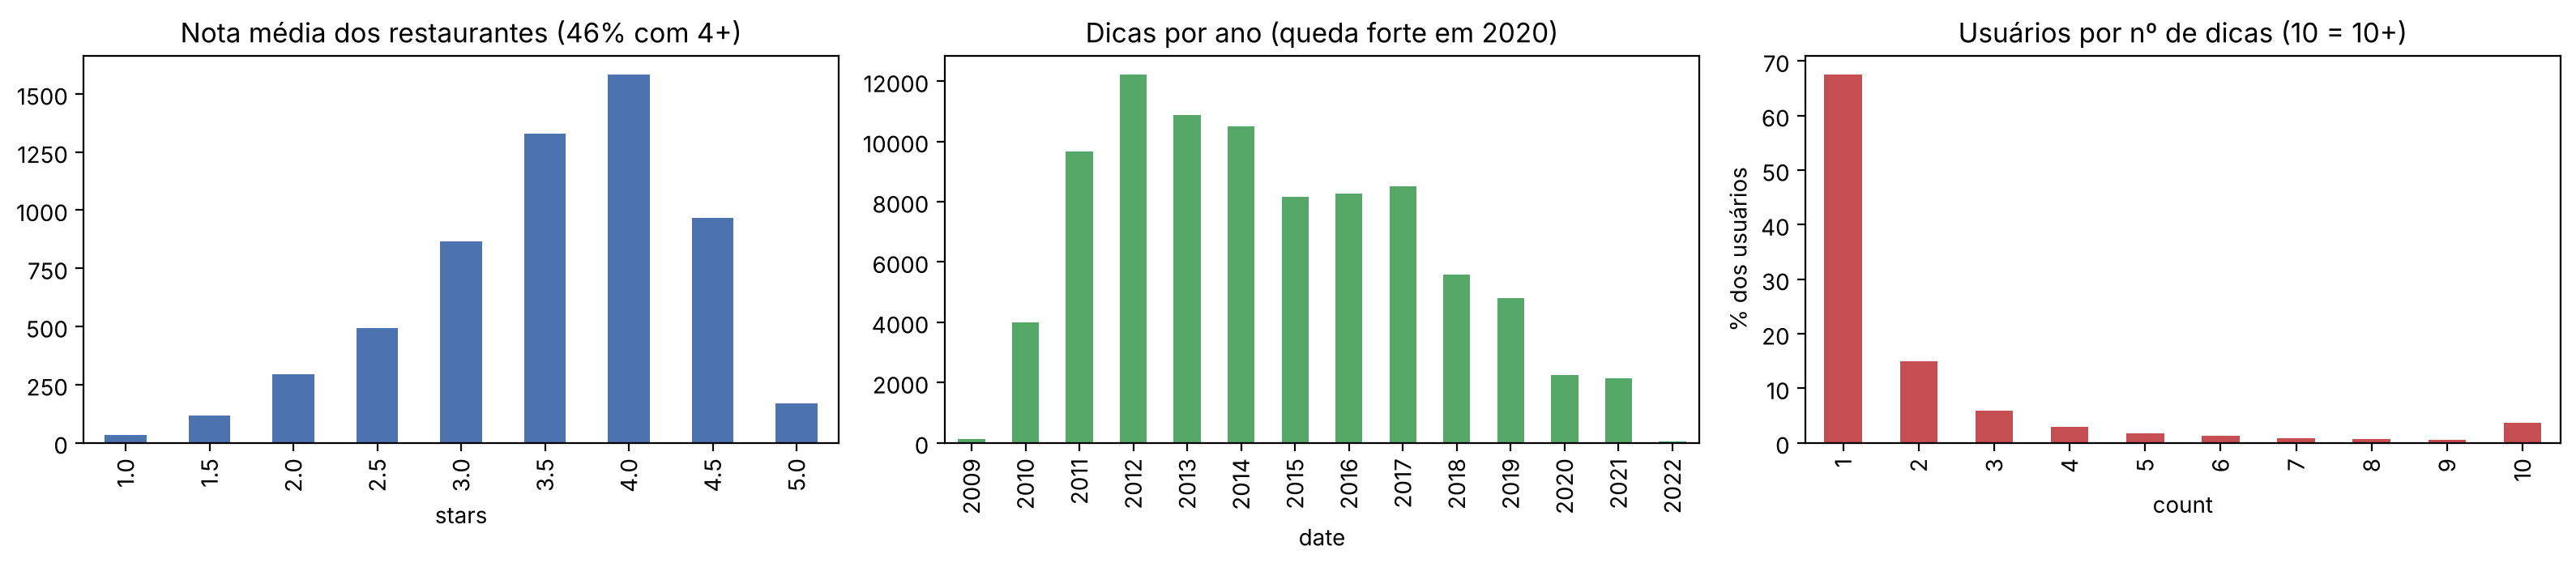

Usuários com 1 dica só: 68% -> cold start também aqui


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
biz["stars"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title(f"Nota média dos restaurantes ({(biz['stars'] >= 4).mean():.0%} com 4+)"); ax[0].set_xlabel("stars")
tip["date"].dt.year.value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868")
ax[1].set_title("Dicas por ano (queda forte em 2020)")
dicas_por_usuario = tip["user_id"].value_counts()
(dicas_por_usuario.clip(upper=10).value_counts().sort_index() / len(dicas_por_usuario) * 100).plot.bar(ax=ax[2], color="#C44E52")
ax[2].set_title("Usuários por nº de dicas (10 = 10+)"); ax[2].set_ylabel("% dos usuários")
plt.tight_layout(); plt.savefig(SAIDA / "01_bases.png", dpi=120); plt.show()
print(f"Usuários com 1 dica só: {(dicas_por_usuario == 1).mean():.0%} -> cold start também aqui")

## 2. Data Preparation

| Problema | Decisão | Risco aceito |
|---|---|---|
| Atributos em texto (`"True"`, `"u'free'"`, `"None"`) | parser: booleanos 0/1, ordinais para barulho e álcool | perder nuances raras (`"paid"` no Wi-Fi) |
| Atributos-dicionário (`Ambience`, `GoodForMeal`, `BusinessParking`) | uma coluna 0/1 por chave | — |
| Faixa de preço ausente (≈16%) | imputar pela mediana das culinárias do restaurante + indicador | preço errado para restaurante atípico |
| Demais atributos ausentes (até ≈48%) | mediana **dentro do pipeline** + indicador de ausência | ausência pode significar cadastro pobre (MNAR), e o indicador guarda isso |
| `categories` em texto livre | multi-hot das culinárias com 60+ restaurantes | culinárias raras somem |
| Dicas duplicadas (mesmo usuário, negócio e horário) | remover | — |
| Check-ins numa string só | explodir em linhas e converter para horário local | horário de verão ignorado |
| `review_count`, `is_open` | fora dos atributos (contagem das próprias avaliações e estado atual) | — |

In [5]:
def limpar(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return np.nan
    if isinstance(v, str):
        v = v.strip()
        if v in ("None", "none", "'none'", "u'none'"):
            return np.nan
        if v in ("True", "False"):
            return float(v == "True")
        if v.startswith("{"):
            try:
                return ast.literal_eval(v)
            except (ValueError, SyntaxError):
                return np.nan
        if v.startswith(("u'", "'")):
            return v.lstrip("u").strip("'")
    return v

attrs = biz["attributes"].apply(lambda d: d if isinstance(d, dict) else {})
A = lambda k: attrs.apply(lambda d: limpar(d.get(k)))

rest = pd.DataFrame({"business_id": biz["business_id"], "nome": biz["name"], "stars": biz["stars"],
                     "review_count": biz["review_count"],       # fora dos atributos; só para segmentar e para o app
                     "is_open": biz["is_open"], "lat": biz["latitude"], "lon": biz["longitude"]})
rest["preco"] = pd.to_numeric(A("RestaurantsPriceRange2"), errors="coerce")
for col, chave in [("delivery", "RestaurantsDelivery"), ("takeout", "RestaurantsTakeOut"),
                   ("reservas", "RestaurantsReservations"), ("mesas_fora", "OutdoorSeating"),
                   ("criancas", "GoodForKids"), ("grupos", "RestaurantsGoodForGroups"), ("tv", "HasTV"),
                   ("cartao", "BusinessAcceptsCreditCards"), ("atende_mesa", "RestaurantsTableService")]:
    rest[col] = pd.to_numeric(A(chave), errors="coerce")
rest["alcool"] = A("Alcohol").map({"none": 0, "beer_and_wine": 1, "full_bar": 2})
rest["barulho"] = A("NoiseLevel").map({"quiet": 0, "average": 1, "loud": 2, "very_loud": 3})
rest["wifi_gratis"] = A("WiFi").map({"free": 1.0, "no": 0.0, "paid": 0.0})

for chave, prefixo, subs in [("Ambience", "amb", ["casual", "classy", "trendy", "hipster", "romantic", "intimate", "divey", "upscale", "touristy"]),
                             ("GoodForMeal", "ref", ["breakfast", "brunch", "lunch", "dinner", "latenight", "dessert"]),
                             ("BusinessParking", "estac", ["street", "lot", "garage", "valet"])]:
    dic = A(chave)
    for s in subs:
        rest[f"{prefixo}_{s}"] = dic.apply(lambda d: float(bool(d.get(s))) if isinstance(d, dict) and d.get(s) is not None else np.nan)

# horário de funcionamento
def horas(h):
    if not isinstance(h, dict):
        return np.nan, np.nan, np.nan
    total, fecha_tarde = 0.0, 0
    for intervalo in h.values():
        a, b = intervalo.split("-")
        ha, hb = (int(x.split(":")[0]) + int(x.split(":")[1]) / 60 for x in (a, b))
        dur = (hb - ha) % 24 or (24 if intervalo != "0:0-0:0" else 0)
        total += dur
        fecha_tarde |= (hb >= 22 or hb < ha)
    return total, float("Sunday" in h), float(fecha_tarde)
rest[["horas_semana", "abre_domingo", "fecha_tarde"]] = pd.DataFrame(biz["hours"].apply(horas).tolist())
rest["n_atributos"] = attrs.apply(len)

# culinárias: multi-hot das categorias de comida com 60+ restaurantes
GENERICAS = {"Restaurants", "Food", "Nightlife", "Event Planning & Services", "Caterers", "Specialty Food",
             "Food Delivery Services", "Shopping", "Grocery", "Convenience Stores", "Arts & Entertainment",
             "Beer", "Wine & Spirits", "Food Trucks", "Juice Bars & Smoothies", "Ethnic Food", "Venues & Event Spaces",
             "Local Flavor", "Imported Food", "Lounges", "Sports Bars", "Wine Bars", "Cocktail Bars", "Pubs", "Dive Bars"}
lista_cat = biz["categories"].fillna("").str.split(", ")
contagem = Counter(c for cs in lista_cat for c in cs if c not in GENERICAS)
CULINARIAS = [c for c, n in contagem.most_common() if n >= 60]
rest["culinarias"] = lista_cat.apply(lambda cs: [c for c in cs if c in CULINARIAS])
for c in CULINARIAS:
    rest[f"cul_{c}"] = rest["culinarias"].apply(lambda cs: float(c in cs))
rest["n_culinarias"] = rest["culinarias"].apply(len)

# preço ausente: mediana das culinárias do restaurante
rest["preco_ausente"] = rest["preco"].isna().astype(int)
med = {c: rest.loc[rest[f"cul_{c}"] == 1, "preco"].median() for c in CULINARIAS}
def imputar_preco(r):
    if not np.isnan(r["preco"]):
        return r["preco"]
    vals = [med[c] for c in r["culinarias"] if not np.isnan(med[c])]
    return float(np.median(vals)) if vals else np.nan
rest["preco"] = rest.apply(imputar_preco, axis=1).fillna(rest["preco"].median())

print(f"{len(CULINARIAS)} culinárias viraram colunas: {', '.join(CULINARIAS[:12])}, ...")
print(f"Preço ausente: {rest['preco_ausente'].mean():.1%} | delivery declarado: {(rest['delivery'] == 1).mean():.1%}")

50 culinárias viraram colunas: Bars, Sandwiches, Pizza, American (New), Breakfast & Brunch, American (Traditional), Coffee & Tea, Italian, Chinese, Fast Food, Burgers, Seafood, ...
Preço ausente: 15.6% | delivery declarado: 59.4%


In [6]:
# ---- check-ins: uma linha por check-in, em horário local
ck = chk[["business_id", "date"]].assign(date=chk["date"].str.split(", ")).explode("date")
ck["ts"] = pd.to_datetime(ck["date"]) - pd.Timedelta(hours=5)          # UTC -> Philadelphia (aprox.)
FIM = ck["ts"].max()
g = ck.groupby("business_id")["ts"]
feat_ck = pd.DataFrame({
    "chk_total": g.size(),
    "chk_anos_ativo": (g.max() - g.min()).dt.days / 365.25 + 0.25,
    "chk_share_jantar": g.apply(lambda s: s.dt.hour.between(17, 21).mean()),
    "chk_share_fds": g.apply(lambda s: (s.dt.dayofweek >= 5).mean()),
    "chk_share_ult2anos": g.apply(lambda s: (s >= FIM - pd.Timedelta(days=730)).mean()),
})
feat_ck["chk_por_ano"] = feat_ck["chk_total"] / feat_ck["chk_anos_ativo"]

# ---- dicas: volume, elogios e tom do texto (léxico simples, só para dar uma régua)
antes = len(tip)
tip = tip.drop_duplicates(["user_id", "business_id", "date"]).sort_values("date").reset_index(drop=True)
POS = r"\b(?:great|best|love|loved|amazing|delicious|awesome|excellent|fantastic|perfect|favorite|tasty|yummy|fresh|friendly|good)\b"
NEG = r"\b(?:worst|bad|terrible|rude|cold|slow|avoid|horrible|awful|disgusting|overpriced|dirty|bland|never|mediocre|wrong)\b"
txt = tip["text"].str.lower()
tip["tom_pos"] = txt.str.contains(POS).astype(int)
tip["tom_neg"] = txt.str.contains(NEG).astype(int)
g = tip.groupby("business_id")
feat_tip = pd.DataFrame({"tips_total": g.size(), "tips_usuarios": g["user_id"].nunique(),
                         "tips_elogios": g["compliment_count"].sum(),
                         "tips_tom_pos": g["tom_pos"].mean(), "tips_tom_neg": g["tom_neg"].mean()})

rest = rest.merge(feat_ck, left_on="business_id", right_index=True, how="left") \
           .merge(feat_tip, left_on="business_id", right_index=True, how="left")
for c in ["chk_total", "chk_por_ano", "tips_total", "tips_usuarios", "tips_elogios"]:
    rest[c] = rest[c].fillna(0)
    rest[c + "_log"] = np.log1p(rest[c])
rest["tips_por_chk"] = rest["tips_total"] / (rest["chk_total"] + 1)
rest["tips_saldo_tom"] = rest["tips_tom_pos"] - rest["tips_tom_neg"]
print(f"Dicas duplicadas removidas: {antes - len(tip)} | check-ins processados: {len(ck):,}")
rest[["chk_total", "chk_por_ano", "chk_share_jantar", "chk_share_fds", "tips_total", "tips_tom_pos", "tips_tom_neg"]].describe().T.round(2)

Dicas duplicadas removidas: 11 | check-ins processados: 1,227,522


,count,mean,std,min,25%,50%,75%,max
chk_total,5855.0,209.65,532.84,0.0,11.00,46.00,178.00,18615.00
chk_por_ano,5855.0,28.88,52.86,0.0,4.00,10.98,31.67,1522.65
chk_share_jantar,5655.0,0.39,0.26,0.0,0.17,0.41,0.58,1.00
chk_share_fds,5655.0,0.36,0.19,0.0,0.25,0.36,0.46,1.00
tips_total,5855.0,14.88,30.54,0.0,2.00,5.00,15.00,827.00
tips_tom_pos,5223.0,0.45,0.29,0.0,0.27,0.47,0.63,1.00
tips_tom_neg,5223.0,0.08,0.16,0.0,0.00,0.00,0.09,1.00


### 2.1 A hipótese do BU com dados reais
O Data Understanding da P2 usou a amostra sintética. Aqui os mesmos testes são refeitos com as dicas reais de
Philadelphia (o `review.json` não está disponível, então a dica faz o papel da avaliação):

- **Esparsidade e cauda longa:** quão vazia é a matriz usuário × restaurante e quanto da atenção vai para poucos
  restaurantes.
- **Gosto concentrado:** para quem deixou 6+ dicas em restaurantes diferentes, a culinária favorita é definida com a
  **primeira metade** das dicas e medida na **segunda metade**. Se o gosto fosse aleatório, a fatia da favorita na
  segunda metade seria igual à fatia dessa culinária no total de dicas da cidade.
- **Satisfação:** o tom positivo das dicas na culinária favorita contra as demais (aproxima a comparação de notas do
  slide 2.5, que exigia o `review.json`).

In [7]:
pares = tip.drop_duplicates(["user_id", "business_id"])          # tip já está em ordem de data: fica a 1ª visita
por_rest = tip.groupby("business_id").size().reindex(rest["business_id"], fill_value=0).sort_values(ascending=False)
x = np.sort(por_rest.to_numpy(dtype=float))
gini_tips = float((2 * np.arange(1, len(x) + 1) - len(x) - 1) @ x / (len(x) * x.sum()))
ano = tip["date"].dt.year.value_counts()

cul_rest = dict(zip(rest["business_id"], rest["culinarias"]))
fatia_cidade = Counter(c for b in pares["business_id"] for c in cul_rest[b])
fatia_cidade = {c: n / len(pares) for c, n in fatia_cidade.items()}
contagem_u = pares["user_id"].value_counts()
obs, esp, tom_fav, tom_outras = [], [], [], []
for uid, g in pares[pares["user_id"].isin(contagem_u[contagem_u >= 6].index)].groupby("user_id"):
    culs = [cul_rest[b] for b in g["business_id"]]
    meio = len(culs) // 2
    cont = Counter(c for cs in culs[:meio] for c in cs)
    if not cont:
        continue
    fav = cont.most_common(1)[0][0]
    na_fav = np.array([fav in cs for cs in culs[meio:]])
    tom = g["tom_pos"].to_numpy()[meio:]
    obs.append(na_fav.mean()); esp.append(fatia_cidade[fav])
    tom_fav += list(tom[na_fav]); tom_outras += list(tom[~na_fav])

du_real = pd.Series({
    "esparsidade da matriz usuário × restaurante (%)": 100 * (1 - len(pares) / (pares["user_id"].nunique() * len(rest))),
    "usuários com 1 dica só (%)": 100 * (contagem_u == 1).mean(),
    "top 10% dos restaurantes: fatia das dicas (%)": 100 * por_rest.head(len(por_rest) // 10).sum() / por_rest.sum(),
    "Gini das dicas por restaurante": gini_tips,
    "variação das dicas 2019 -> 2020 (%)": 100 * (ano.get(2020, 0) / ano.get(2019, np.nan) - 1),
    "usuários no teste de gosto (6+ restaurantes)": len(obs),
    "fatia da culinária favorita na 2ª metade (%)": 100 * np.mean(obs),
    "fatia esperada ao acaso (%)": 100 * np.mean(esp),
    "dicas com tom positivo na favorita (%)": 100 * np.mean(tom_fav),
    "dicas com tom positivo nas demais (%)": 100 * np.mean(tom_outras),
}, name="Philadelphia, dados reais")
du_real.round(2).to_csv(SAIDA / "DU_hipotese_real.csv")
dif = np.array(obs) - np.array(esp)
t = stats.ttest_1samp(dif, 0)
print(f"Gosto concentrado: +{100 * dif.mean():.1f} p.p. acima do acaso (t = {t.statistic:.1f}, p = {t.pvalue:.1e}, "
      f"{len(dif)} usuários)")
du_real.round(2).to_frame()

Gosto concentrado: +6.2 p.p. acima do acaso (t = 14.1, p = 2.9e-43, 2080 usuários)


,"Philadelphia, dados reais"
esparsidade da matriz usuário × restaurante (%),99.96
usuários com 1 dica só (%),69.73
top 10% dos restaurantes: fatia das dicas (%),54.13
Gini das dicas por restaurante,0.69
variação das dicas 2019 -> 2020 (%),-53.37
usuários no teste de gosto (6+ restaurantes),2080.00
fatia da culinária favorita na 2ª metade (%),23.39
fatia esperada ao acaso (%),17.19
dicas com tom positivo na favorita (%),35.51
dicas com tom positivo nas demais (%),37.10


## 3. Ferramentas comuns aos dois modelos
- `pipeline()`: mediana com indicador de ausência + escala (necessária para logística e KNN) + modelo, tudo aprendido
  só no treino.
- `melhor_limiar()`: escolhe o limiar que maximiza o **F0,5** (pesa a precisão 2× mais que o recall), porque o falso
  positivo é o erro caro.
- `avaliar()`: matriz de confusão em percentuais. **% do total** = fatia de todos os casos do teste; **taxa de FP** =
  FP ÷ casos negativos reais; **taxa de FN** = FN ÷ casos positivos reais.

In [8]:
def pipeline(modelo):
    return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                     ("sc", StandardScaler()), ("clf", modelo)])


class Score:
    # baseline sem aprendizado: usa uma coluna como pontuação (ex.: popularidade)
    def __init__(self, coluna, sinal=1): self.coluna, self.sinal = coluna, sinal
    def fit(self, X, y): return self
    def predict_proba(self, X):
        s = self.sinal * X[self.coluna].to_numpy(dtype=float)
        s = np.nan_to_num(s, nan=np.nanmin(s))
        p = (s - s.min()) / (s.max() - s.min() + 1e-12)
        return np.c_[1 - p, p]


def melhor_limiar(y, p, beta=0.5):
    grade = np.unique(np.quantile(p, np.linspace(0.02, 0.98, 97)))
    if len(grade) < 2:
        return 0.0                                             # modelo constante: recomenda tudo
    f = [fbeta_score(y, (p >= t).astype(int), beta=beta, zero_division=0) for t in grade]
    return float(grade[int(np.argmax(f))])


def avaliar(y, p, limiar):
    y = np.asarray(y); pred = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel(); n = tn + fp + fn + tp
    return {"Acertos (% do total)": 100 * (tp + tn) / n, "Falso positivo (% do total)": 100 * fp / n,
            "Falso negativo (% do total)": 100 * fn / n, "VP (% do total)": 100 * tp / n, "VN (% do total)": 100 * tn / n,
            "Taxa de FP (FP ÷ negativos)": 100 * fp / max(fp + tn, 1), "Taxa de FN (FN ÷ positivos)": 100 * fn / max(fn + tp, 1),
            "Precisão": 100 * precision_score(y, pred, zero_division=0), "Recall": 100 * recall_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5}


COLS = ["Acertos (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)",
        "Taxa de FP (FP ÷ negativos)", "Taxa de FN (FN ÷ positivos)", "Precisão", "Recall", "AUC", "Limiar"]

def tabela(res):
    return (res[COLS].style.format({c: "{:.1f}%" for c in COLS[:7]} | {"AUC": "{:.3f}", "Limiar": "{:.3f}"})
            .background_gradient(subset=["Falso positivo (% do total)"], cmap="Reds")
            .background_gradient(subset=["Acertos (% do total)", "AUC"], cmap="Greens"))


def grafico_composicao(res, titulo, arquivo, rot_pos, rot_neg):
    comp = res[["VP (% do total)", "VN (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)"]].astype(float)
    cores = ["#2E7D32", "#81C784", "#C62828", "#F9A825"]
    rot = [f"Acerto: {rot_pos}", f"Acerto: {rot_neg}", "Falso positivo", "Falso negativo"]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(comp) + 1.6)); esq = np.zeros(len(comp))
    for c, cor, r in zip(comp.columns, cores, rot):
        ax.barh(comp.index, comp[c], left=esq, color=cor, label=r)
        for i, (v, e) in enumerate(zip(comp[c], esq)):
            if v >= 4: ax.text(e + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
        esq += comp[c].to_numpy()
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% dos casos do teste"); ax.set_title(titulo)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=8)
    plt.tight_layout(); plt.savefig(SAIDA / arquivo, dpi=120); plt.show()


def grafico_matrizes(y, probas, limiares, rotulos, arquivo):
    nomes = list(probas); ncol = 4; nlin = int(np.ceil(len(nomes) / ncol))
    fig, axes = plt.subplots(nlin, ncol, figsize=(16, 3.8 * nlin))
    for ax, nome in zip(axes.ravel(), nomes):
        pred = (probas[nome] >= limiares[nome]).astype(int)
        ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=[0, 1], normalize="all") * 100,
                               display_labels=rotulos).plot(ax=ax, colorbar=False, values_format=".1f", cmap="Blues")
        ax.set_title(nome, fontsize=10); ax.set_xlabel("previsto (%)"); ax.set_ylabel("real")
    for ax in axes.ravel()[len(nomes):]: ax.axis("off")
    plt.tight_layout(); plt.savefig(SAIDA / arquivo, dpi=120); plt.show()


def modelos_padrao(prof_arvore):
    return {
        "Regressão logística": pipeline(LogisticRegression(max_iter=3000)),
        "Árvore de decisão": pipeline(DecisionTreeClassifier(max_depth=prof_arvore, min_samples_leaf=20, random_state=SEED)),
        "Random forest": pipeline(RandomForestClassifier(n_estimators=300, max_depth=14, min_samples_leaf=10,
                                                         n_jobs=-1, random_state=SEED)),
        "Gradient boosting": pipeline(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED)),
        "KNN (k=50)": pipeline(KNeighborsClassifier(n_neighbors=50, weights="distance")),
    }

## 4. Modelo A · Os consumidores aprovam este restaurante?

- **Alvo:** `aprovado = 1` se `stars ≥ 4` (≈47% dos restaurantes, classes quase equilibradas).
- **Grão:** 1 linha = 1 restaurante. Como `stars` é uma fotografia sem data, o split é **aleatório estratificado**
  (75/25), e o limiar é escolhido com **validação cruzada dentro do treino**: o teste é usado uma vez só.
- **Três conjuntos de atributos**, para medir o valor de cada fonte:

| Conjunto | Atributos | Quando existe |
|---|---|---|
| **Cadastro** | preço, delivery, reservas, ambiente, refeições, estacionamento, horário, culinárias, localização | desde o 1º dia do restaurante (*cold start*) |
| **+ Comportamento** | check-ins (volume, ritmo, jantar, fim de semana, tendência) e volume de dicas | depois de algum movimento |
| **+ Tom das dicas** | fatia de dicas com palavras positivas e negativas | depois de algumas dicas |

**Fora do modelo:** `review_count` (é a contagem das mesmas avaliações que formam o alvo) e `is_open` (estado atual,
que pode ser consequência da nota).

**Papel do modelo A no app:** para um restaurante com muitas avaliações, a nota de hoje já existe e é legítima na hora
de recomendar. O modelo A é necessário onde essa nota não existe ou é instável: casas novas ou com poucas avaliações
(o *cold start* do lado do restaurante). Por isso a seção 4.1 olha o desempenho por número de avaliações.

Treino 4,391 | teste 1,464 | aprovados: 46.5%


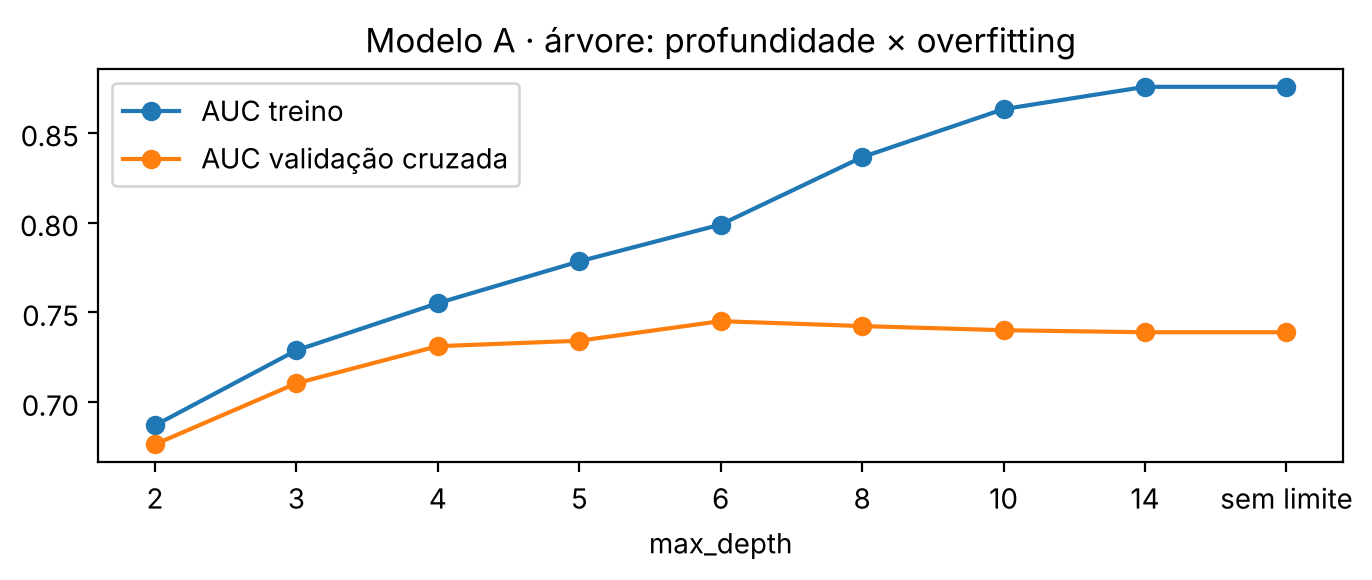

Profundidade escolhida: 6


In [9]:
CAD = (["preco", "preco_ausente", "delivery", "takeout", "reservas", "mesas_fora", "criancas", "grupos", "tv",
        "cartao", "atende_mesa", "alcool", "barulho", "wifi_gratis", "horas_semana", "abre_domingo", "fecha_tarde",
        "n_atributos", "n_culinarias", "lat", "lon"]
       + [c for c in rest.columns if c.startswith(("amb_", "ref_", "estac_", "cul_"))])
COMP = ["chk_total_log", "chk_por_ano_log", "chk_anos_ativo", "chk_share_jantar", "chk_share_fds", "chk_share_ult2anos",
        "tips_total_log", "tips_usuarios_log", "tips_elogios_log", "tips_por_chk"]
TOM = ["tips_tom_pos", "tips_tom_neg", "tips_saldo_tom"]
CONJUNTOS = {"Cadastro": CAD, "Cadastro + comportamento": CAD + COMP, "Cadastro + comportamento + tom": CAD + COMP + TOM}

rest["aprovado"] = (rest["stars"] >= 4).astype(int)
idx_tr, idx_te = train_test_split(rest.index, test_size=0.25, stratify=rest["aprovado"], random_state=SEED)
yA_tr, yA_te = rest.loc[idx_tr, "aprovado"], rest.loc[idx_te, "aprovado"]
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(f"Treino {len(idx_tr):,} | teste {len(idx_te):,} | aprovados: {rest['aprovado'].mean():.1%}")

# profundidade da árvore por validação cruzada (conjunto completo)
XA_full = rest.loc[idx_tr, CONJUNTOS["Cadastro + comportamento + tom"]]
curva = []
for prof in [2, 3, 4, 5, 6, 8, 10, 14, None]:
    m = pipeline(DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, random_state=SEED))
    cv_auc = cross_val_score(m, XA_full, yA_tr, cv=CV, scoring="roc_auc").mean()
    tr_auc = roc_auc_score(yA_tr, m.fit(XA_full, yA_tr).predict_proba(XA_full)[:, 1])
    curva.append({"max_depth": "sem limite" if prof is None else prof, "AUC treino": tr_auc, "AUC validação cruzada": cv_auc})
curva = pd.DataFrame(curva)
PROF_A = curva.loc[curva["AUC validação cruzada"].idxmax(), "max_depth"]
PROF_A = None if PROF_A == "sem limite" else int(PROF_A)
ax = curva.set_index(curva["max_depth"].astype(str))[["AUC treino", "AUC validação cruzada"]].plot(marker="o", figsize=(7, 3))
ax.set_title("Modelo A · árvore: profundidade × overfitting"); plt.tight_layout(); plt.savefig(SAIDA / "A_curva_arvore.png", dpi=120); plt.show()
print("Profundidade escolhida:", PROF_A)

In [10]:
resA, probA, limA = {}, {}, {}
for nome_conj, cols in CONJUNTOS.items():
    Xtr, Xte = rest.loc[idx_tr, cols], rest.loc[idx_te, cols]
    modelos = {"Chute: todos aprovados": DummyClassifier(strategy="prior"),
               "Popularidade (check-ins)": Score("chk_total_log")} if nome_conj == "Cadastro + comportamento" else {}
    modelos |= modelos_padrao(PROF_A)
    for nome, m in modelos.items():
        chave = nome if nome.startswith(("Chute", "Popularidade")) else f"{nome} · {nome_conj}"
        cv_p = (m.predict_proba(Xtr)[:, 1] if isinstance(m, Score)
                else cross_val_predict(m, Xtr, yA_tr, cv=CV, method="predict_proba")[:, 1])
        limA[chave] = melhor_limiar(yA_tr, cv_p)
        m.fit(Xtr, yA_tr)
        probA[chave] = m.predict_proba(Xte)[:, 1]
        resA[chave] = avaliar(yA_te, probA[chave], limA[chave]) | {"Limiar": limA[chave], "conjunto": nome_conj, "modelo": nome}
    print(f"ok: {nome_conj}")

resA = pd.DataFrame(resA).T
for c in resA.columns.drop(["conjunto", "modelo"]): resA[c] = resA[c].astype(float)
resA.sort_values("AUC", ascending=False).to_csv(SAIDA / "A_metricas_teste.csv", float_format="%.3f")

# AUC por modelo × conjunto: quanto cada fonte de dados acrescenta
pivo = resA[~resA.index.str.startswith(("Chute", "Popularidade"))].pivot(index="modelo", columns="conjunto", values="AUC")[list(CONJUNTOS)]
pivo.round(3)

ok: Cadastro


ok: Cadastro + comportamento


ok: Cadastro + comportamento + tom


conjunto,Cadastro,Cadastro + comportamento,Cadastro + comportamento + tom
modelo,,,
Gradient boosting,0.794,0.799,0.816
KNN (k=50),0.756,0.765,0.771
Random forest,0.786,0.801,0.821
Regressão logística,0.779,0.795,0.813
Árvore de decisão,0.713,0.735,0.752


**Leitura:** o cadastro sozinho (o que existe para um restaurante novo) já separa parte dos aprovados; check-ins e dicas
acrescentam; o tom das dicas acrescenta mais, porque é opinião do consumidor. A tabela abaixo detalha o conjunto
completo, que é o usado no top 5.

In [11]:
CONJ_A = "Cadastro + comportamento + tom"
selA = resA[(resA["conjunto"] == CONJ_A) | resA.index.str.startswith(("Chute", "Popularidade"))].copy()
selA.index = selA.index.str.replace(f" · {CONJ_A}", "", regex=False)
selA = selA.sort_values("AUC", ascending=False)
tabela(selA)

,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Taxa de FP (FP ÷ negativos),Taxa de FN (FN ÷ positivos),Precisão,Recall,AUC,Limiar
Random forest,74.3%,8.0%,17.7%,14.9%,38.0%,78.3%,62.0%,0.821,0.532
Gradient boosting,74.3%,6.6%,19.1%,12.3%,41.1%,80.7%,58.9%,0.816,0.648
Regressão logística,73.4%,8.9%,17.7%,16.7%,38.0%,76.3%,62.0%,0.813,0.569
KNN (k=50),69.7%,15.6%,14.8%,29.1%,31.7%,67.1%,68.3%,0.771,0.426
Árvore de decisão,70.8%,14.4%,14.8%,26.9%,31.9%,68.7%,68.1%,0.752,0.512
Popularidade (check-ins),52.9%,33.4%,13.7%,62.5%,29.4%,49.6%,70.6%,0.588,0.305
Chute: todos aprovados,46.5%,53.5%,0.0%,100.0%,0.0%,46.5%,100.0%,0.500,0.465


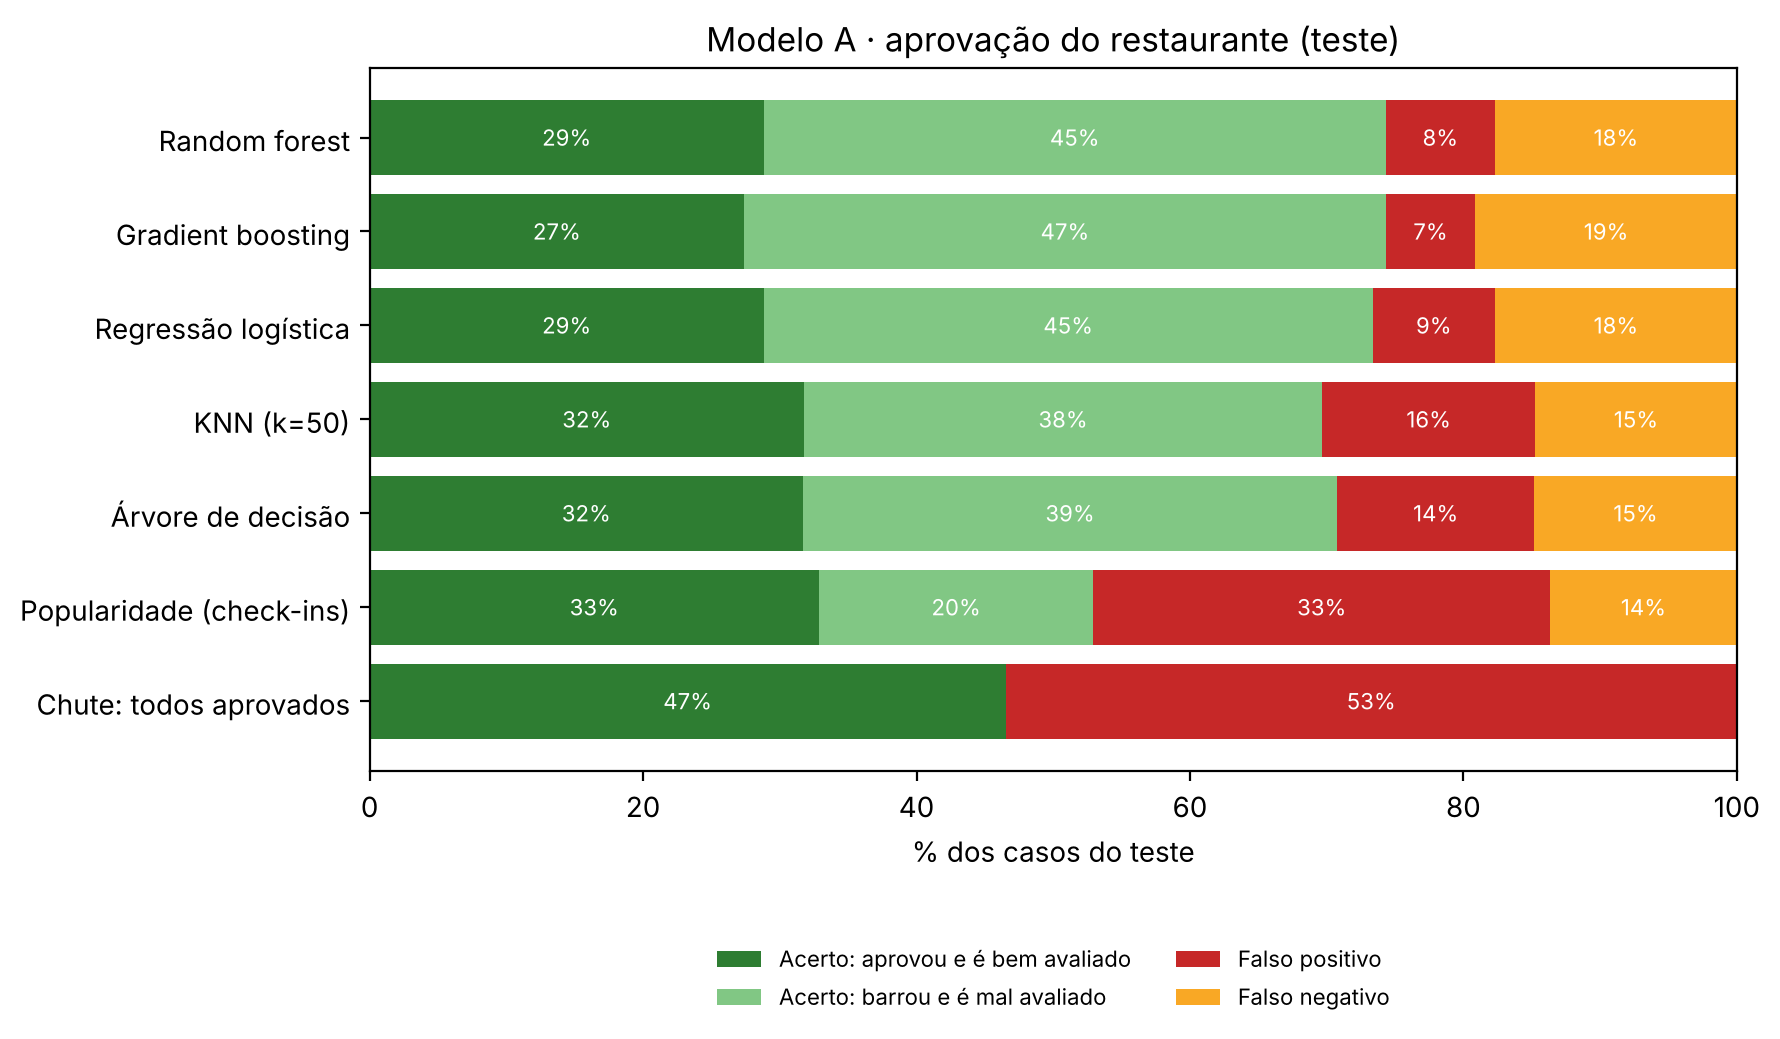

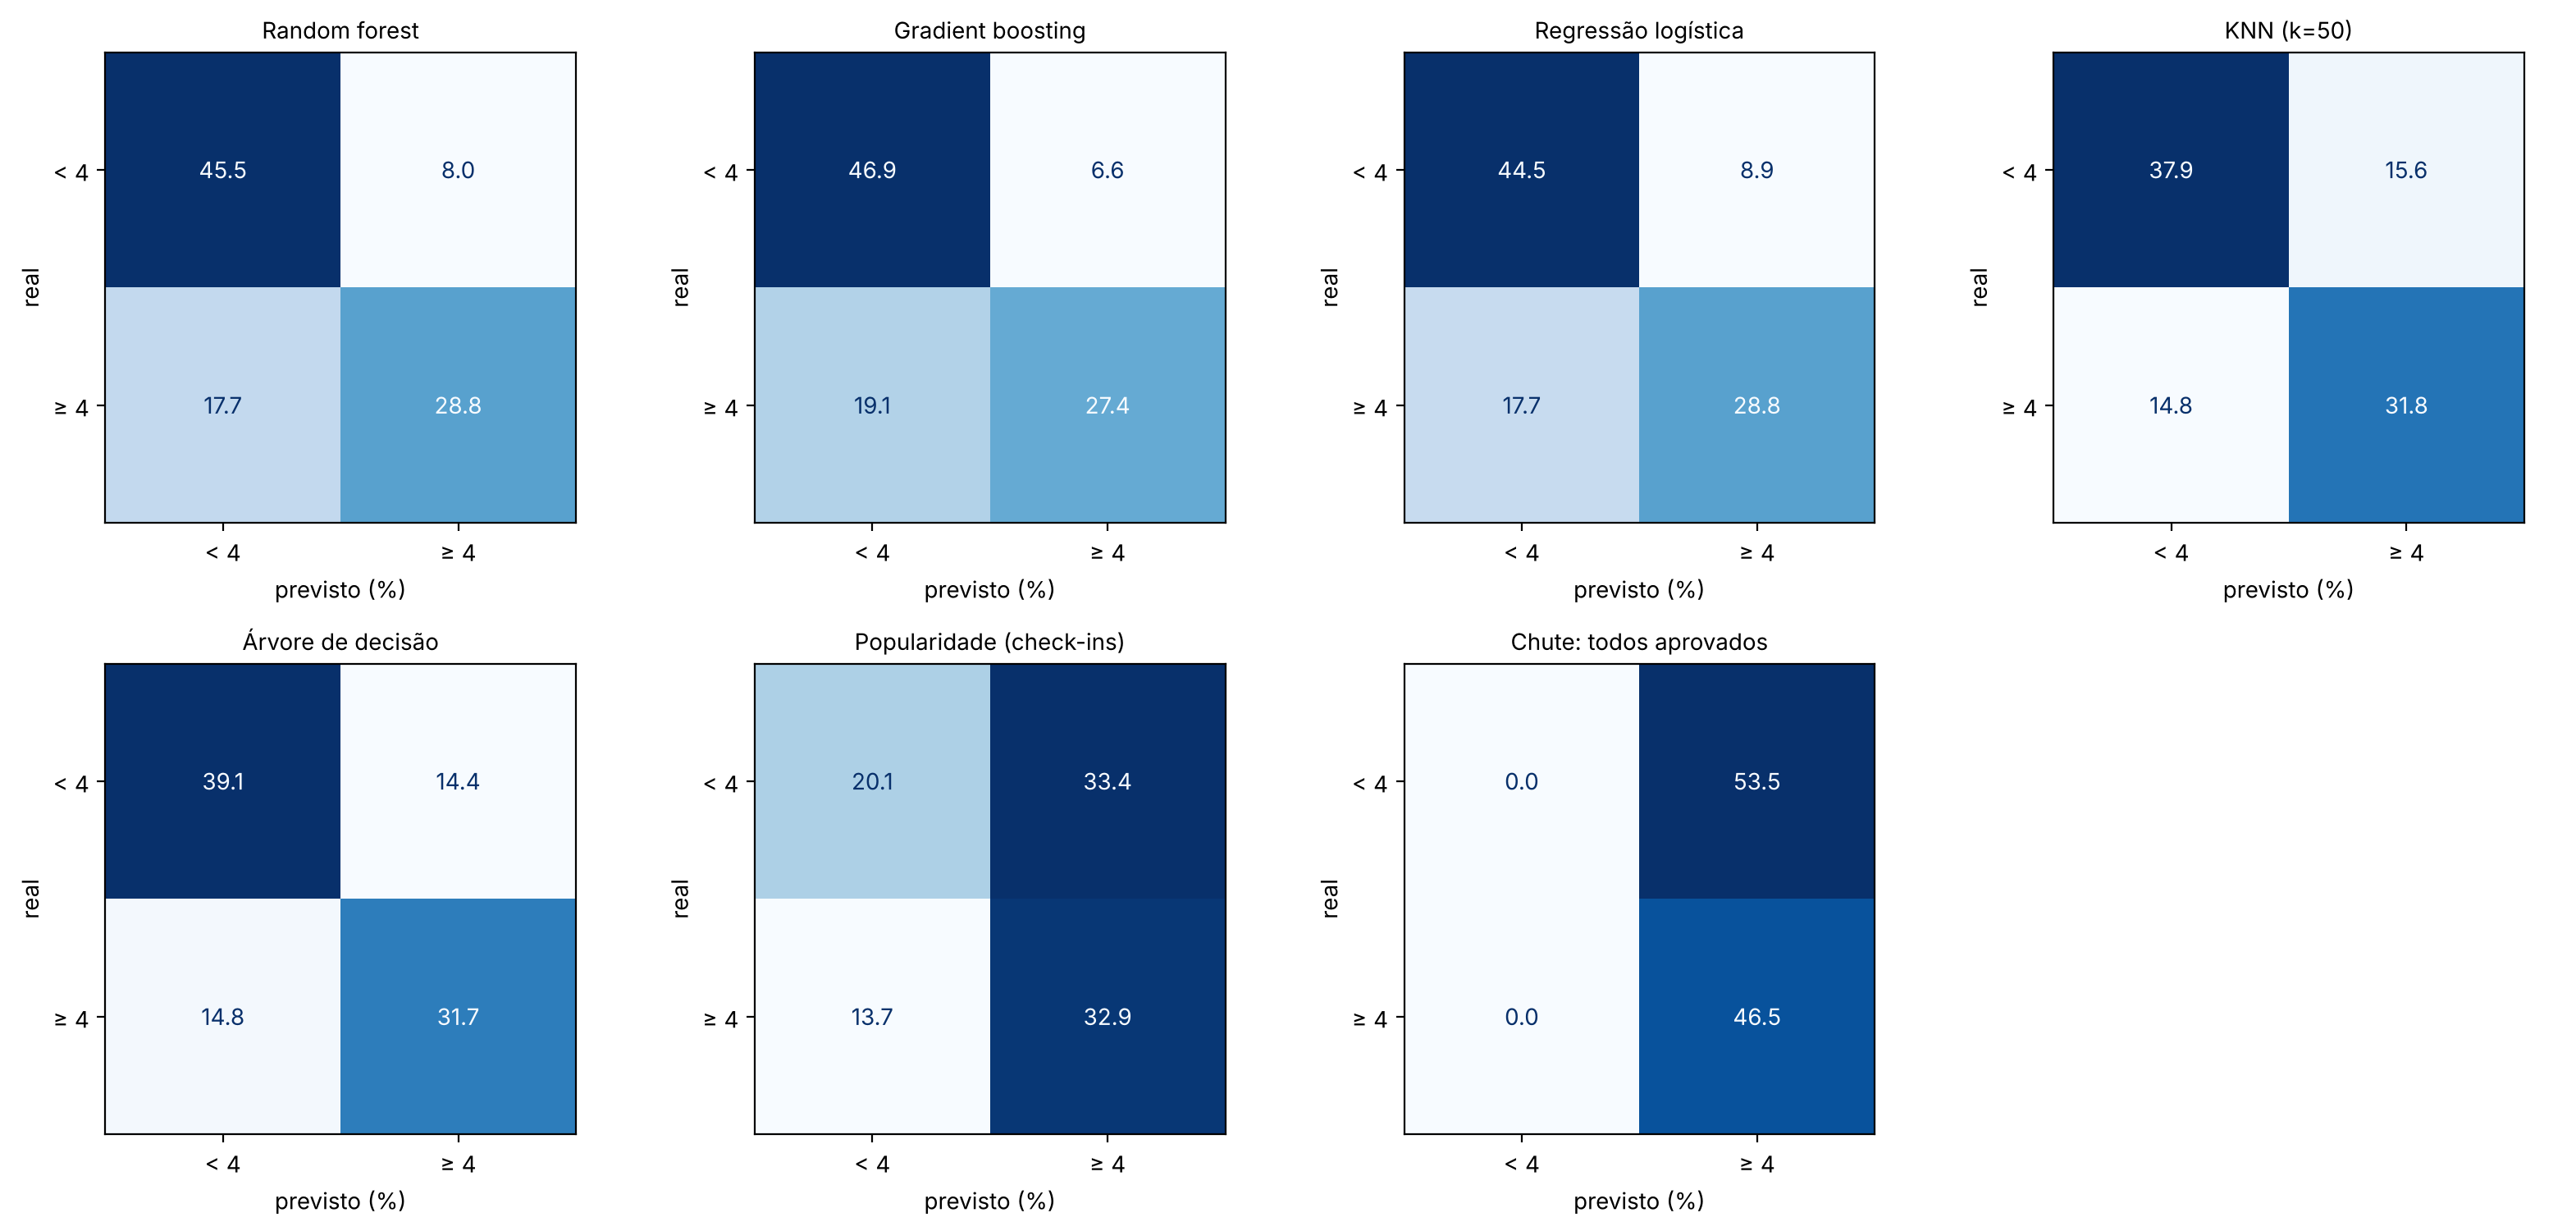

In [12]:
grafico_composicao(selA, "Modelo A · aprovação do restaurante (teste)", "A_composicao_erros.png",
                   "aprovou e é bem avaliado", "barrou e é mal avaliado")
probA_sel = {n: probA[n if n.startswith(("Chute", "Popularidade")) else f"{n} · {CONJ_A}"] for n in selA.index}
limA_sel = {n: limA[n if n.startswith(("Chute", "Popularidade")) else f"{n} · {CONJ_A}"] for n in selA.index}
grafico_matrizes(yA_te, probA_sel, limA_sel, ["< 4", "≥ 4"], "A_matrizes_confusao.png")

In [13]:
# Segmento de interesse do negócio: restaurantes que fazem delivery
MELHOR_A = selA.drop([i for i in selA.index if i.startswith(("Chute", "Popularidade"))])["AUC"].idxmax()
deliv = (rest.loc[idx_te, "delivery"] == 1).to_numpy()
seg = pd.DataFrame({rot: avaliar(yA_te.to_numpy()[m], probA_sel[MELHOR_A][m], limA_sel[MELHOR_A])
                    for rot, m in [("faz delivery", deliv), ("não faz / não informa", ~deliv)]}).T
seg.insert(0, "n", [int(deliv.sum()), int((~deliv).sum())])
print("Melhor modelo A:", MELHOR_A)
seg[["n"] + COLS[:8]].round({c: 1 for c in COLS[:7]} | {"AUC": 3})

Melhor modelo A: Random forest


,n,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Taxa de FP (FP ÷ negativos),Taxa de FN (FN ÷ positivos),Precisão,Recall,AUC
faz delivery,860,75.9,8.8,15.2,16.5,32.9,77.8,67.1,0.837
não faz / não informa,604,72.0,6.8,21.2,12.8,45.2,79.1,54.8,0.795


### 4.1 Onde o modelo A decide no app: restaurantes com poucas avaliações
No app, a nota observada vale para quem tem 20+ avaliações; o modelo A decide abaixo disso. Esta tabela mostra o
desempenho de A por faixa de avaliações, com o cadastro sozinho (o que uma casa nova tem) e com o conjunto completo.
Nas faixas pequenas a própria nota média é ruidosa, então o alvo também é mais difícil de acertar.

In [14]:
rc = rest.loc[idx_te, "review_count"].to_numpy()
yA = yA_te.to_numpy()
linhas = []
for rot, m in [("menos de 20 avaliações (A decide no app)", rc < 20), ("20 a 99", (rc >= 20) & (rc < 100)),
               ("100 ou mais", rc >= 100)]:
    for conj in ["Cadastro", CONJ_A]:
        chave = f"{MELHOR_A} · {conj}"
        if m.sum() == 0 or len(np.unique(yA[m])) < 2:
            continue
        r = avaliar(yA[m], probA[chave][m], limA[chave])
        linhas.append({"faixa": rot, "atributos": conj, "restaurantes": int(m.sum()), "% aprovados": 100 * yA[m].mean(),
                       **{k: r[k] for k in ["Acertos (% do total)", "Falso positivo (% do total)",
                                            "Taxa de FP (FP ÷ negativos)", "Precisão", "AUC"]}})
segA = pd.DataFrame(linhas).set_index(["faixa", "atributos"])
segA.to_csv(SAIDA / "A_por_n_avaliacoes.csv", float_format="%.3f")
print("Modelo A:", MELHOR_A)
segA.round({c: 1 for c in segA.columns if c not in ("AUC", "restaurantes")} | {"AUC": 3})

Modelo A: Random forest


restaurantes  % aprovados  Acertos (% do total)  Falso positivo (% do total)  \
faixa                                    atributos                                                                                                      
menos de 20 avaliações (A decide no app) Cadastro                                 481         39.3                  69.6                          7.1   
                                         Cadastro + comportamento + tom           481         39.3                  69.9                          4.8   
20 a 99                                  Cadastro                                 591         41.3                  72.3                         10.2   
                                         Cadastro + comportamento + tom           591         41.3                  76.0                          8.3   
100 ou mais                              Cadastro                                 392         63.3                  70.4                          9.2   
                                         Cadastro + comportamento + tom           392         63.3                  77.3                         11.5   

                                                                         Taxa de FP (FP ÷ negativos)  Precisão    AUC  
faixa                                    atributos                                                                     
menos de 20 avaliações (A decide no app) Cadastro                                               11.6      69.4  0.739  
                                         Cadastro + comportamento + tom                          7.9      74.4  0.744  
20 a 99                                  Cadastro                                               17.3      70.0  0.787  
                                         Cadastro + comportamento + tom                         14.1      75.5  0.839  
100 ou mais                              Cadastro                                               25.0      82.4  0.791  
                                         Cadastro + comportamento + tom                         31.2      81.9  0.831

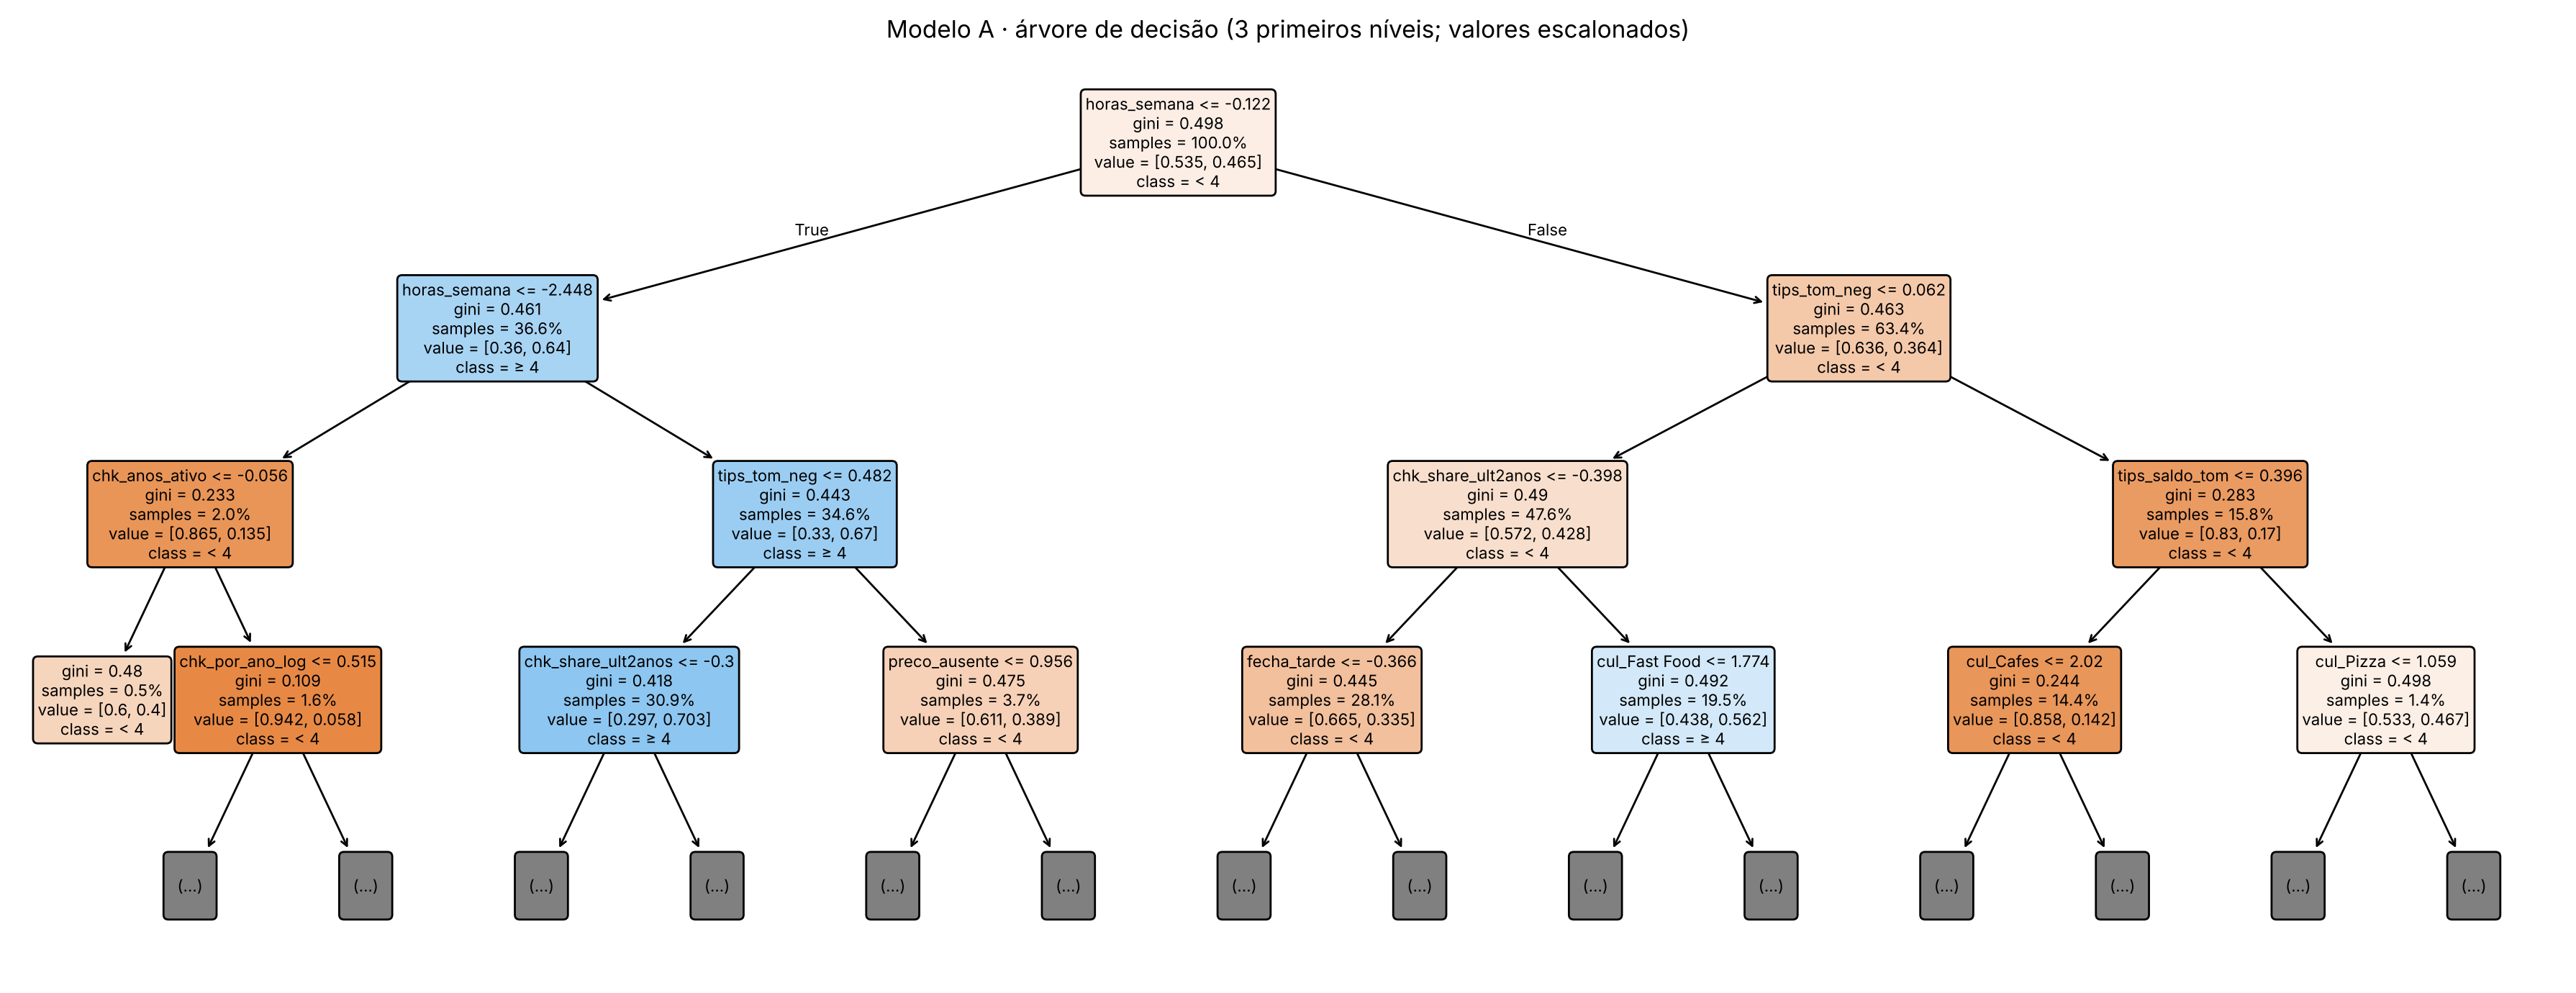

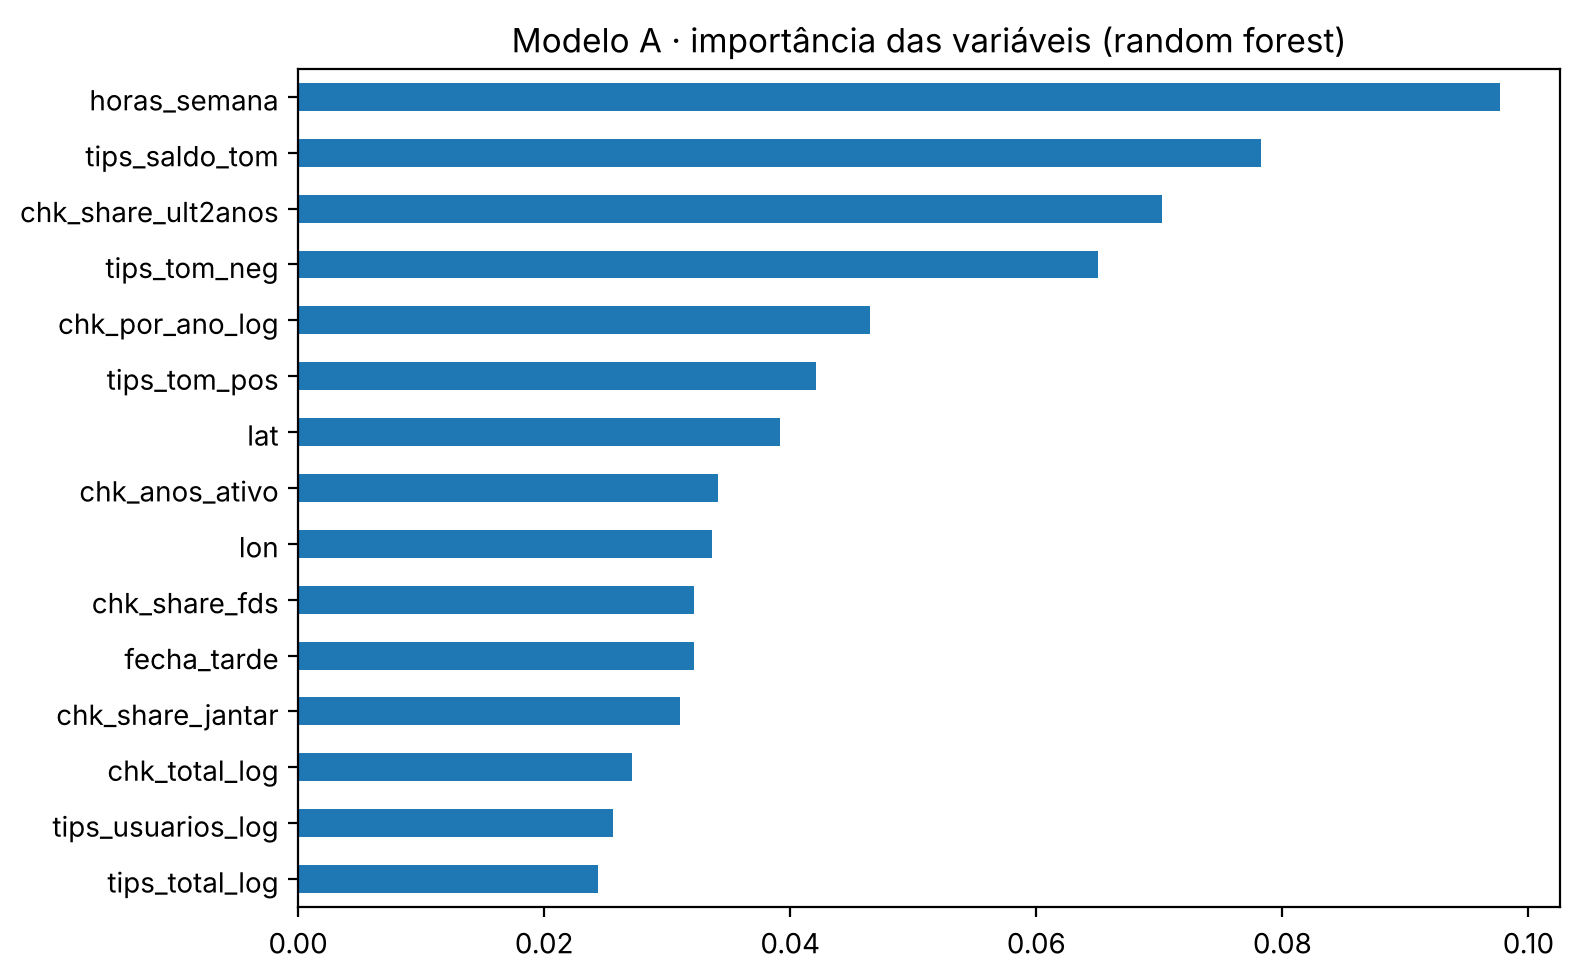

In [15]:
# Interpretação: árvore (3 níveis) e importâncias
cols_A = CONJUNTOS[CONJ_A]
arvA = pipeline(DecisionTreeClassifier(max_depth=PROF_A, min_samples_leaf=20, random_state=SEED)).fit(rest.loc[idx_tr, cols_A], yA_tr)
nomes_A = [n.replace("missingindicator_", "ausente_") for n in arvA.named_steps["imp"].get_feature_names_out(cols_A)]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvA.named_steps["clf"], max_depth=3, feature_names=nomes_A, class_names=["< 4", "≥ 4"], filled=True,
          proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Modelo A · árvore de decisão (3 primeiros níveis; valores escalonados)")
plt.tight_layout(); plt.savefig(SAIDA / "A_arvore.png", dpi=110); plt.show()

rfA = modelos_padrao(PROF_A)["Random forest"].fit(rest.loc[idx_tr, cols_A], yA_tr)
pd.Series(rfA.named_steps["clf"].feature_importances_, index=nomes_A).sort_values().tail(15) \
  .plot.barh(figsize=(8, 5), title="Modelo A · importância das variáveis (random forest)")
plt.tight_layout(); plt.savefig(SAIDA / "A_importancias.png", dpi=120); plt.show()

## 5. Modelo B · Este consumidor vai escolher este restaurante?

Sem notas individuais, usamos a **preferência revelada**: deixar uma dica num restaurante mostra que a pessoa foi lá.
É o mesmo raciocínio de "o que você pediu antes" dos apps de entrega.

**Protocolo (anti-vazamento):**
1. Cada dica (a partir de 2011) de um usuário que **já tinha deixado pelo menos uma dica antes** vira um caso
   positivo, desde que o restaurante seja novo para ele (descoberta, não repetição).
2. Para cada positivo sorteamos **4 restaurantes que ele nunca tinha visitado** e que já existiam na data, de forma
   **uniforme** (o mesmo protocolo do HitRate@5 do Data Understanding). Assim a popularidade é um baseline forte e
   justo: as pessoas de fato vão mais aos restaurantes movimentados, e o modelo precisa superar isso.
3. Todos os atributos usam só o que existia **antes** da data da dica:

| Grupo | Atributo |
|---|---|
| Gosto | `afin_max`, `afin_media`: fatia das dicas anteriores do usuário nas culinárias do candidato |
| Lugar | `dist_centroide_km`, `dist_min_km`: distância até onde ele costuma ir (o Yelp não tem o endereço do usuário; o histórico de lugares faz esse papel) |
| Bolso e canal | `user_preco_medio`, `dif_preco`, `user_share_delivery`, `match_delivery` |
| Candidato | preço, delivery, check-ins e dicas **até a data**, check-ins nos 365 dias anteriores, idade |
| Experiência | `user_n_prev` (quantas dicas anteriores) |

4. **Split temporal:** treino até 2016, validação em 2017 (limiar e profundidade), teste de 2018 em diante.

Com 1 positivo para 4 negativos, chutar "ninguém escolhe" acerta 80%: de novo, olhamos a matriz inteira.

Cada positivo e seus 4 negativos formam um **caso** (`caso`). Além da matriz de confusão, a seção 5.1 mede o
**ranking**: em quantos casos o restaurante escolhido fica em 1º entre os 5 (HitRate@1; ao acaso, 20%) e o
**MRR** (média de 1 ÷ posição do escolhido; ao acaso, 0,457). É a versão deste protocolo da Precision@5 prometida no BU.

In [16]:
t0 = time.time()
rng = np.random.default_rng(SEED)
R = rest.reset_index(drop=True)
bid2i = {b: i for i, b in enumerate(R["business_id"])}
cul_idx = {c: k for k, c in enumerate(CULINARIAS)}
cats_i = [np.array([cul_idx[c] for c in cs], dtype=int) for cs in R["culinarias"]]
LAT, LON = np.radians(R["lat"].to_numpy()), np.radians(R["lon"].to_numpy())
PRECO = R["preco"].to_numpy(); DELIV = R["delivery"].to_numpy()

EPOCA, UM_S = pd.Timestamp("1970-01-01"), pd.Timedelta(seconds=1)
segundos = lambda s: ((s - EPOCA) // UM_S).astype("int64")          # datas -> segundos (independe da unidade)
ck_ts = {bid2i[b]: np.sort(segundos(s).to_numpy()) for b, s in ck.groupby("business_id")["ts"]}
tip["t"] = segundos(tip["date"])
tip_ts = {bid2i[b]: np.sort(s.to_numpy()) for b, s in tip.groupby("business_id")["t"]}
vazio = np.array([], dtype="int64")
primeira = np.array([min(ck_ts.get(i, [np.inf])[0] if len(ck_ts.get(i, vazio)) else np.inf,
                         tip_ts.get(i, [np.inf])[0] if len(tip_ts.get(i, vazio)) else np.inf) for i in range(len(R))])
acum = np.cumsum(np.full(len(R), 1 / len(R)))          # sorteio uniforme dos negativos (protocolo do HitRate do DU)
ANO = 365.25 * 86400


def km(lat1, lon1, lat2, lon2):
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def antes(arr, t):
    return int(np.searchsorted(arr, t, side="left")) if arr is not None else 0


def linha(estado, c, t):
    # atributos do par (usuário no instante t, restaurante candidato c), só com o passado
    n, cont, lats, lons = estado["n"], estado["cont"], estado["lats"], estado["lons"]
    sh = cont[cats_i[c]] / n if len(cats_i[c]) else np.array([0.0])
    d = km(LAT[c], LON[c], np.array(lats), np.array(lons))
    cent = km(LAT[c], LON[c], np.mean(lats), np.mean(lons))
    upm = estado["preco_soma"] / n
    usd = estado["deliv_soma"] / estado["deliv_n"] if estado["deliv_n"] else np.nan
    ckc, tpc = ck_ts.get(c), tip_ts.get(c)
    return {"user_n_prev_log": np.log1p(n), "afin_max": sh.max(), "afin_media": sh.mean(),
            "dist_centroide_km": cent, "dist_min_km": d.min(), "user_preco_medio": upm,
            "dif_preco": abs(PRECO[c] - upm), "user_share_delivery": usd, "cand_delivery": DELIV[c],
            "match_delivery": (DELIV[c] * usd) if not np.isnan(DELIV[c]) and not np.isnan(usd) else np.nan,
            "cand_preco": PRECO[c],
            "cand_chk_prev_log": np.log1p(antes(ckc, t)),
            "cand_chk_365d_log": np.log1p(antes(ckc, t) - antes(ckc, t - 365 * 86400)),
            "cand_tips_prev_log": np.log1p(antes(tpc, t)),
            "cand_idade_anos": (t - primeira[c]) / ANO if np.isfinite(primeira[c]) else np.nan}


K_NEG = 4
T_INICIO = int((pd.Timestamp("2011-01-01") - EPOCA) // UM_S)      # antes de 2011 há poucos restaurantes ativos na base
linhas_B, n_caso = [], 0
tip["i"] = tip["business_id"].map(bid2i)
usuarios_multi = tip["user_id"].value_counts()
usuarios_multi = set(usuarios_multi[usuarios_multi >= 2].index)
for uid, grupo in tip[tip["user_id"].isin(usuarios_multi)].groupby("user_id", sort=False):
    est = {"n": 0, "cont": np.zeros(len(CULINARIAS)), "lats": [], "lons": [], "preco_soma": 0.0,
           "deliv_soma": 0.0, "deliv_n": 0}
    vistos = set()
    for i, t, data in zip(grupo["i"].to_numpy(), grupo["t"].to_numpy(), grupo["date"]):
        if est["n"] >= 1 and i not in vistos and t >= T_INICIO:
            negs, tentativas = [], 0
            while len(negs) < K_NEG and tentativas < 30:            # limite evita laço infinito em datas com poucos restaurantes
                tentativas += 1
                for c in np.searchsorted(acum, rng.random(3 * K_NEG)):
                    c = min(int(c), len(R) - 1)
                    if c != i and c not in vistos and primeira[c] <= t and c not in negs:
                        negs.append(c)
                        if len(negs) == K_NEG: break
            if len(negs) == K_NEG:
                for c, y in [(i, 1)] + [(c, 0) for c in negs]:
                    linhas_B.append({"caso": n_caso, "user_id": uid, "business_id": R.at[c, "business_id"],
                                     "date": data, "escolheu": y, **linha(est, c, t)})
                n_caso += 1
        # atualiza o histórico DEPOIS de gerar o caso (o presente não entra no passado)
        est["n"] += 1; est["cont"][cats_i[i]] += 1
        est["lats"].append(LAT[i]); est["lons"].append(LON[i]); est["preco_soma"] += PRECO[i]
        if not np.isnan(DELIV[i]): est["deliv_soma"] += DELIV[i]; est["deliv_n"] += 1
        vistos.add(i)

B = pd.DataFrame(linhas_B)
FEATS_B = [c for c in B.columns if c not in ("caso", "user_id", "business_id", "date", "escolheu")]
B["periodo"] = np.select([B["date"] < "2017-01-01", B["date"] < "2018-01-01"], ["treino", "validacao"], "teste")
print(f"Base B montada em {time.time() - t0:.0f}s: {len(B):,} pares usuário × restaurante, {B['user_id'].nunique():,} usuários")
B.groupby("periodo").agg(pares=("escolheu", "size"), escolhas=("escolheu", "sum"),
                         usuarios=("user_id", "nunique")).loc[["treino", "validacao", "teste"]]

Base B montada em 18s: 199,600 pares usuário × restaurante, 10,142 usuários


,pares,escolhas,usuarios
periodo,,,
treino,156240,31248,7229
validacao,16000,3200,1724
teste,27360,5472,2721


In [17]:
trB, vaB, teB = (B["periodo"] == p for p in ["treino", "validacao", "teste"])
XB_tr, yB_tr = B.loc[trB, FEATS_B], B.loc[trB, "escolheu"]
XB_va, yB_va = B.loc[vaB, FEATS_B], B.loc[vaB, "escolheu"]
XB_te, yB_te = B.loc[teB, FEATS_B], B.loc[teB, "escolheu"]

# profundidade da árvore pela validação
curvaB = []
for prof in [2, 3, 4, 6, 8, 10, 14, None]:
    m = pipeline(DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, random_state=SEED)).fit(XB_tr, yB_tr)
    curvaB.append({"max_depth": "sem limite" if prof is None else prof,
                   "AUC treino": roc_auc_score(yB_tr, m.predict_proba(XB_tr)[:, 1]),
                   "AUC validação": roc_auc_score(yB_va, m.predict_proba(XB_va)[:, 1])})
curvaB = pd.DataFrame(curvaB)
PROF_B = curvaB.loc[curvaB["AUC validação"].idxmax(), "max_depth"]
PROF_B = None if PROF_B == "sem limite" else int(PROF_B)

modelosB = {"Chute: recomenda tudo": DummyClassifier(strategy="prior"),
            "Popularidade (check-ins até a data)": Score("cand_chk_prev_log"),
            "Mais perto (distância)": Score("dist_centroide_km", sinal=-1)} | modelos_padrao(PROF_B)
probB_va, probB_te, limB = {}, {}, {}
for nome, m in modelosB.items():
    if nome.startswith("KNN"):                                  # KNN: amostra do treino para caber no tempo
        amostra = XB_tr.sample(min(60_000, len(XB_tr)), random_state=SEED).index
        m.fit(XB_tr.loc[amostra], yB_tr.loc[amostra])
    else:
        m.fit(XB_tr, yB_tr)
    probB_va[nome], probB_te[nome] = m.predict_proba(XB_va)[:, 1], m.predict_proba(XB_te)[:, 1]
    limB[nome] = melhor_limiar(yB_va, probB_va[nome])
    print(f"{nome:38s} AUC validação = {roc_auc_score(yB_va, probB_va[nome]) if nome[0] != 'C' else 0.5:.3f}")

resB = pd.DataFrame({n: avaliar(yB_te, probB_te[n], limB[n]) | {"Limiar": limB[n]} for n in modelosB}).T.sort_values("AUC", ascending=False)
resB.to_csv(SAIDA / "B_metricas_teste.csv", float_format="%.3f")
print("Profundidade da árvore escolhida:", PROF_B)
tabela(resB)

Chute: recomenda tudo                  AUC validação = 0.500
Popularidade (check-ins até a data)    AUC validação = 0.701


Mais perto (distância)                 AUC validação = 0.690


Regressão logística                    AUC validação = 0.839


Árvore de decisão                      AUC validação = 0.851


Random forest                          AUC validação = 0.859


Gradient boosting                      AUC validação = 0.868


KNN (k=50)                             AUC validação = 0.825
Profundidade da árvore escolhida: 8


,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Taxa de FP (FP ÷ negativos),Taxa de FN (FN ÷ positivos),Precisão,Recall,AUC,Limiar
Gradient boosting,84.9%,2.3%,12.9%,2.8%,64.3%,76.0%,35.7%,0.864,0.440
Random forest,84.5%,4.0%,11.5%,5.0%,57.6%,67.8%,42.4%,0.853,0.363
Árvore de decisão,84.3%,3.1%,12.6%,3.9%,63.0%,70.2%,37.0%,0.842,0.373
Regressão logística,82.2%,3.3%,14.5%,4.2%,72.3%,62.5%,27.7%,0.827,0.312
KNN (k=50),82.2%,4.7%,13.2%,5.8%,65.8%,59.5%,34.2%,0.820,0.384
Mais perto (distância),77.6%,6.8%,15.6%,8.6%,77.9%,39.3%,22.1%,0.679,0.972
Popularidade (check-ins até a data),79.2%,6.5%,14.3%,8.1%,71.6%,46.7%,28.4%,0.633,0.659
Chute: recomenda tudo,20.0%,80.0%,0.0%,100.0%,0.0%,20.0%,100.0%,0.500,0.000


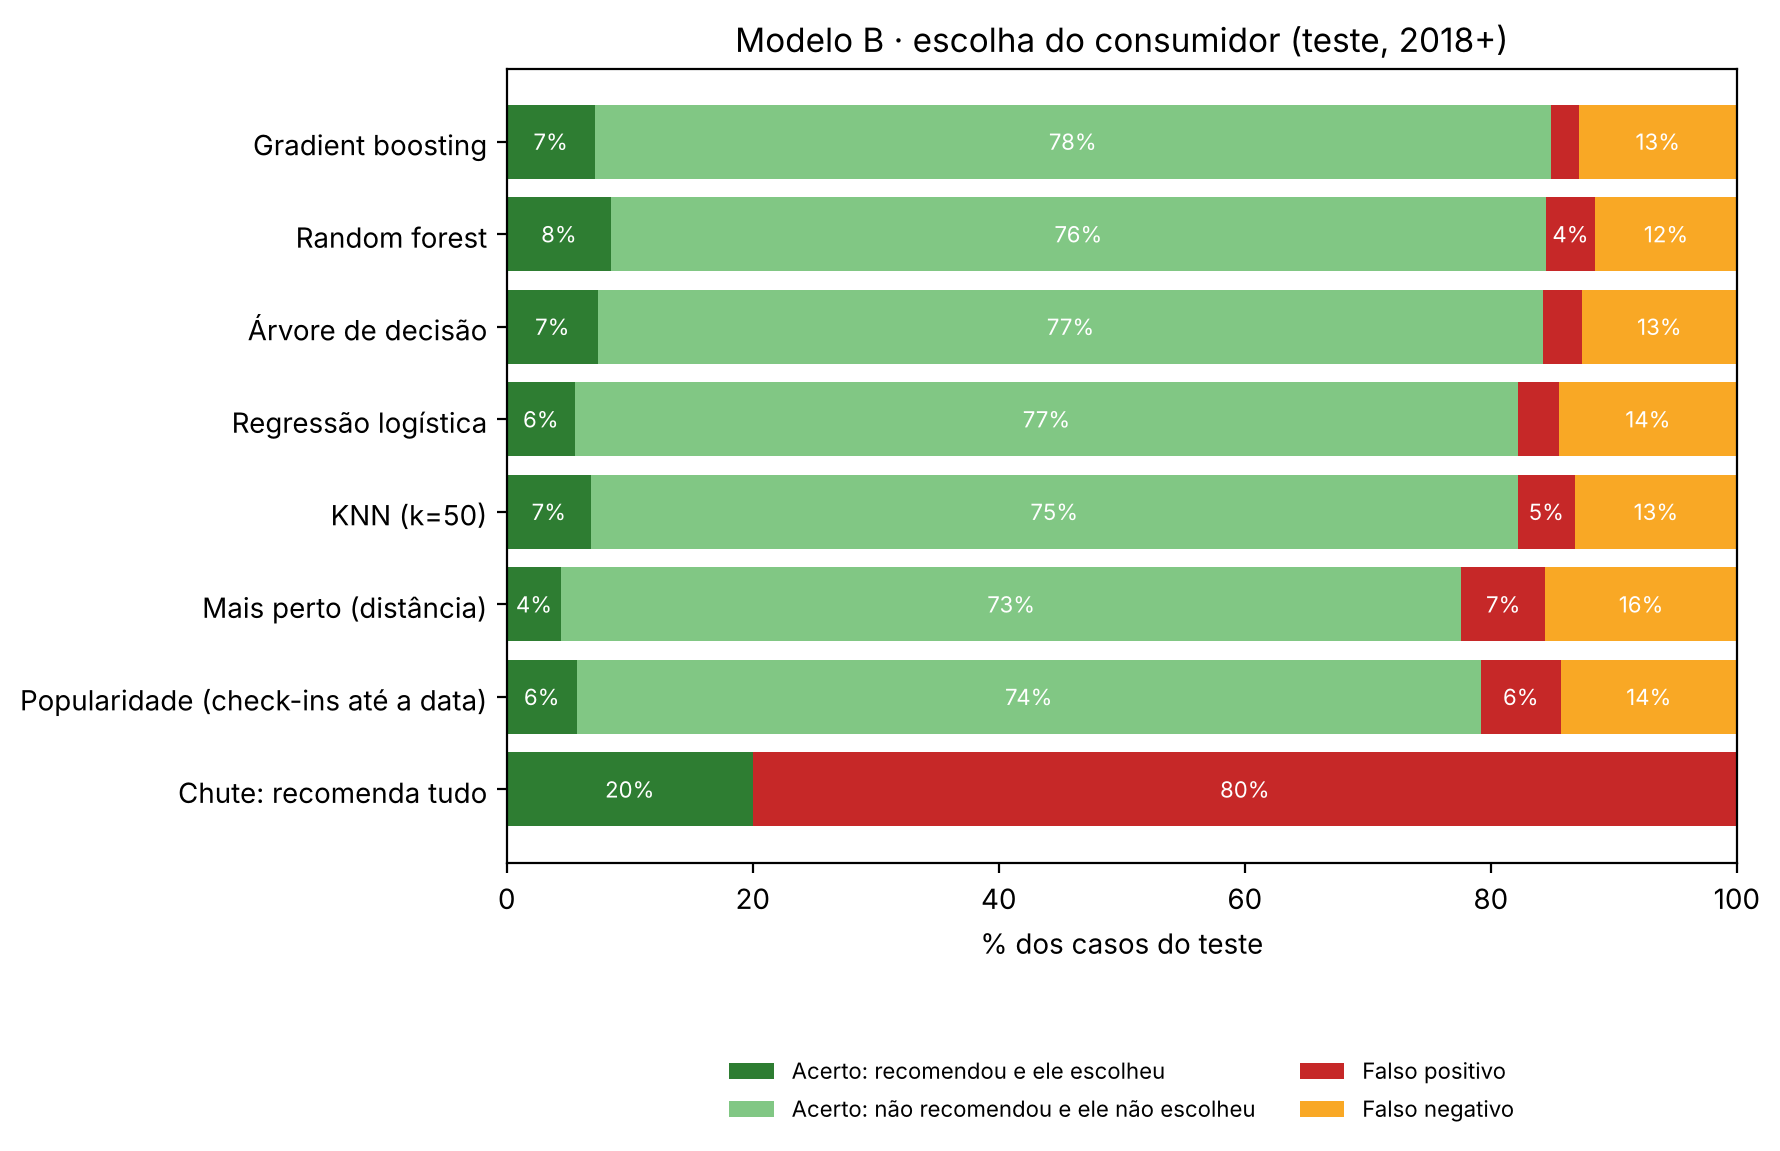

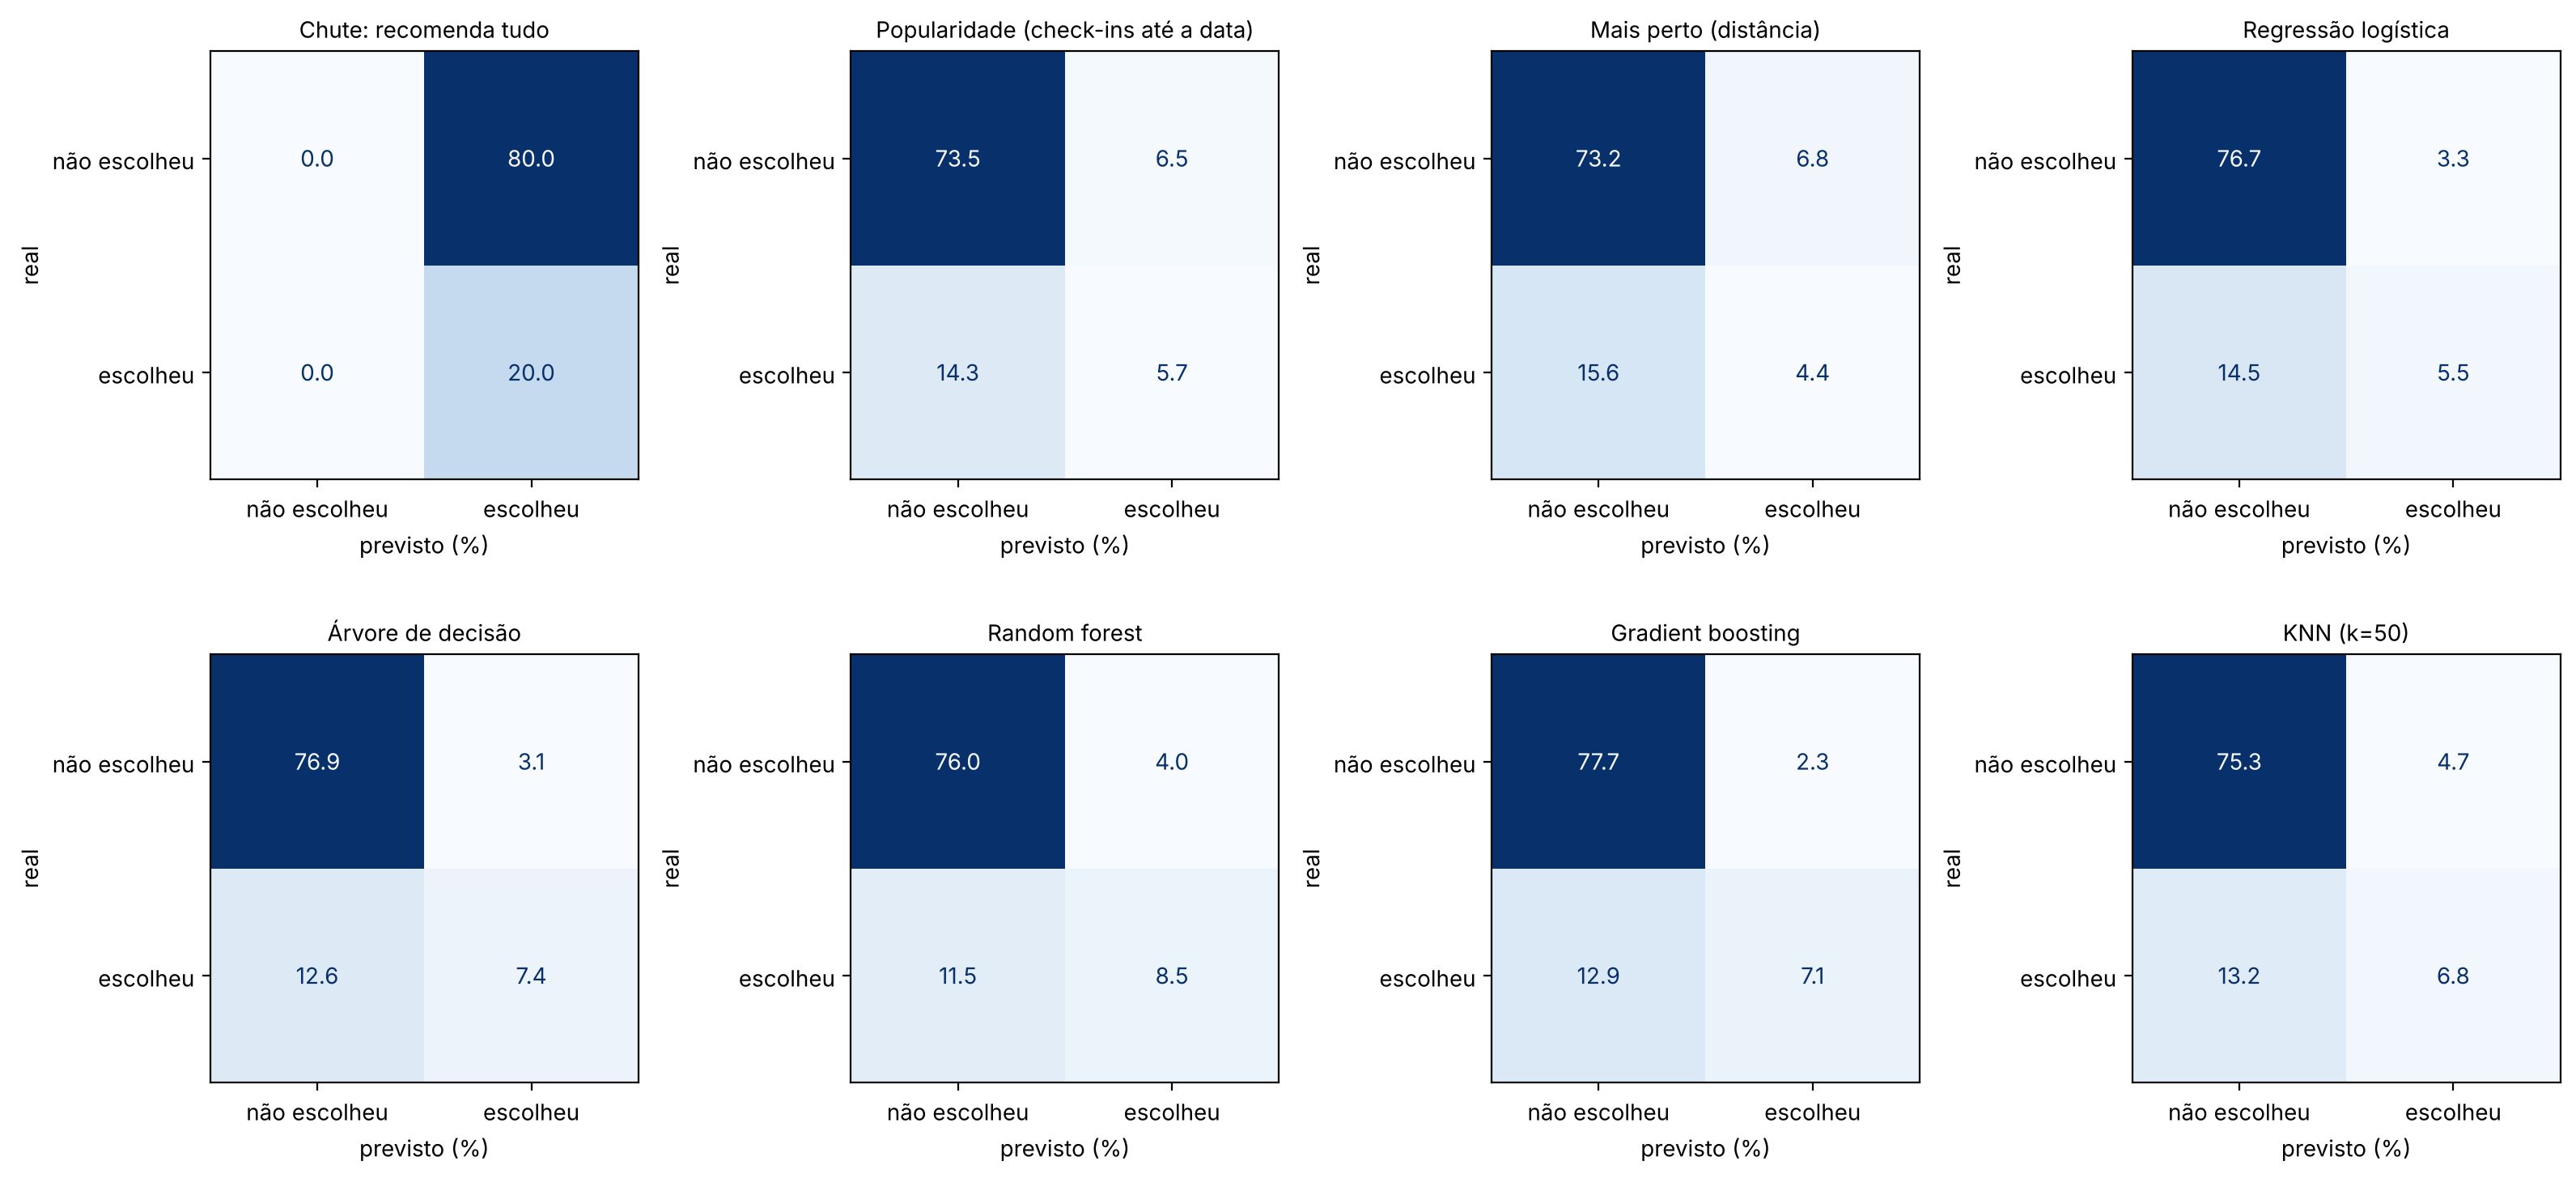

In [18]:
grafico_composicao(resB, "Modelo B · escolha do consumidor (teste, 2018+)", "B_composicao_erros.png",
                   "recomendou e ele escolheu", "não recomendou e ele não escolheu")
grafico_matrizes(yB_te, probB_te, limB, ["não escolheu", "escolheu"], "B_matrizes_confusao.png")

In [19]:
# Por experiência do usuário: o modelo funciona para quem tem pouco histórico?
MELHOR_B = resB.drop([i for i in resB.index if i.startswith(("Chute", "Popularidade", "Mais perto"))])["AUC"].idxmax()
n_prev = np.expm1(XB_te["user_n_prev_log"]).round().to_numpy()
seg = []
for rot, m in [("1 a 2 dicas antes", n_prev <= 2), ("3 a 9 dicas antes", (n_prev >= 3) & (n_prev <= 9)), ("10+ dicas antes", n_prev >= 10)]:
    for nome in [MELHOR_B, "Popularidade (check-ins até a data)"]:
        r = avaliar(yB_te.to_numpy()[m], probB_te[nome][m], limB[nome])
        seg.append({"segmento": rot, "modelo": nome, "pares": int(m.sum()),
                    **{k: r[k] for k in ["Acertos (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)", "Precisão", "AUC"]}})
print("Melhor modelo B:", MELHOR_B)
pd.DataFrame(seg).set_index(["segmento", "modelo"]).round({"Acertos (% do total)": 1, "Falso positivo (% do total)": 1,
                                                          "Falso negativo (% do total)": 1, "Precisão": 1, "AUC": 3})

Melhor modelo B: Gradient boosting


pares  Acertos (% do total)  Falso positivo (% do total)  Falso negativo (% do total)  Precisão    AUC
segmento          modelo                                                                                                                                     
1 a 2 dicas antes Gradient boosting                    12780                  84.1                          1.9                         14.0      75.8  0.851
                  Popularidade (check-ins até a data)  12780                  79.8                          6.7                         13.4      49.4  0.694
3 a 9 dicas antes Gradient boosting                     6870                  84.1                          2.7                         13.2      71.7  0.871
                  Popularidade (check-ins até a data)   6870                  80.0                          6.5                         13.5      50.2  0.709
10+ dicas antes   Gradient boosting                     7710                  86.9                          2.4                         10.7      79.4  0.884
                  Popularidade (check-ins até a data)   7710                  77.4                          6.1                         16.5      36.2  0.461

### 5.1 Ranking: o restaurante escolhido fica em 1º entre os 5 candidatos?
Empates (como no chute, que dá a mesma nota a todos) são desfeitos ao acaso, em média.

In [20]:
def ranking(casos, y, p):
    d = pd.DataFrame({"caso": np.asarray(casos), "y": np.asarray(y), "p": np.asarray(p, dtype=float)})
    pos = d[d["y"] == 1].set_index("caso")["p"]
    neg = d[d["y"] == 0].join(pos.rename("p_pos"), on="caso")
    g = (neg["p"] > neg["p_pos"]).groupby(neg["caso"]).sum().reindex(pos.index).fillna(0).to_numpy()
    t = (neg["p"] == neg["p_pos"]).groupby(neg["caso"]).sum().reindex(pos.index).fillna(0).to_numpy()
    hit1 = np.where(g == 0, 1 / (1 + t), 0.0)                       # empate: posição sorteada entre g+1 e g+t+1
    mrr = np.array([np.mean(1 / np.arange(gi + 1, gi + ti + 2)) for gi, ti in zip(g, t)])
    return {"casos": len(pos), "HitRate@1 (%)": 100 * hit1.mean(), "MRR": mrr.mean()}


casos_te = B.loc[teB, "caso"].to_numpy()
rankB = pd.DataFrame({n: ranking(casos_te, yB_te, probB_te[n]) for n in modelosB}).T.sort_values("MRR", ascending=False)
rankB.to_csv(SAIDA / "B_ranking_teste.csv", float_format="%.3f")
print("Referência ao acaso: HitRate@1 = 20,0% | MRR = 0,457")
rankB.astype({"casos": int}).round({"HitRate@1 (%)": 1, "MRR": 3})

Referência ao acaso: HitRate@1 = 20,0% | MRR = 0,457


,casos,HitRate@1 (%),MRR
Gradient boosting,5472,67.5,0.813
Random forest,5472,66.6,0.804
Árvore de decisão,5472,64.9,0.794
Regressão logística,5472,60.1,0.769
KNN (k=50),5472,58.0,0.752
Mais perto (distância),5472,40.0,0.621
Popularidade (check-ins até a data),5472,40.7,0.603
Chute: recomenda tudo,5472,20.0,0.457


### 5.2 Quanto custa baixar o limiar do modelo B
No app, a casa mal avaliada já é barrada pela guarda de qualidade, então o B serve sobretudo para ordenar. A tabela
mostra, no teste, a precisão e o recall do B com o limiar cheio (F0,5) e com pisos menores.

In [21]:
lb = limB[MELHOR_B]
sensB = pd.DataFrame({f"{f:.0%} do limiar ({f * lb:.2f})": avaliar(yB_te, probB_te[MELHOR_B], f * lb)
                      for f in [1.0, 0.75, 0.5, 0.25]}).T
sensB = sensB[["Precisão", "Recall", "Falso positivo (% do total)", "Taxa de FP (FP ÷ negativos)"]]
sensB.to_csv(SAIDA / "B_limiar_sensibilidade.csv", float_format="%.3f")
print(f"Modelo B ({MELHOR_B}) no teste; referência ao acaso: precisão de 20%")
sensB.round(1)

Modelo B (Gradient boosting) no teste; referência ao acaso: precisão de 20%


,Precisão,Recall,Falso positivo (% do total),Taxa de FP (FP ÷ negativos)
100% do limiar (0.44),76.0,35.7,2.3,2.8
75% do limiar (0.33),65.7,46.7,4.9,6.1
50% do limiar (0.22),55.5,62.8,10.1,12.6
25% do limiar (0.11),43.6,81.6,21.1,26.4


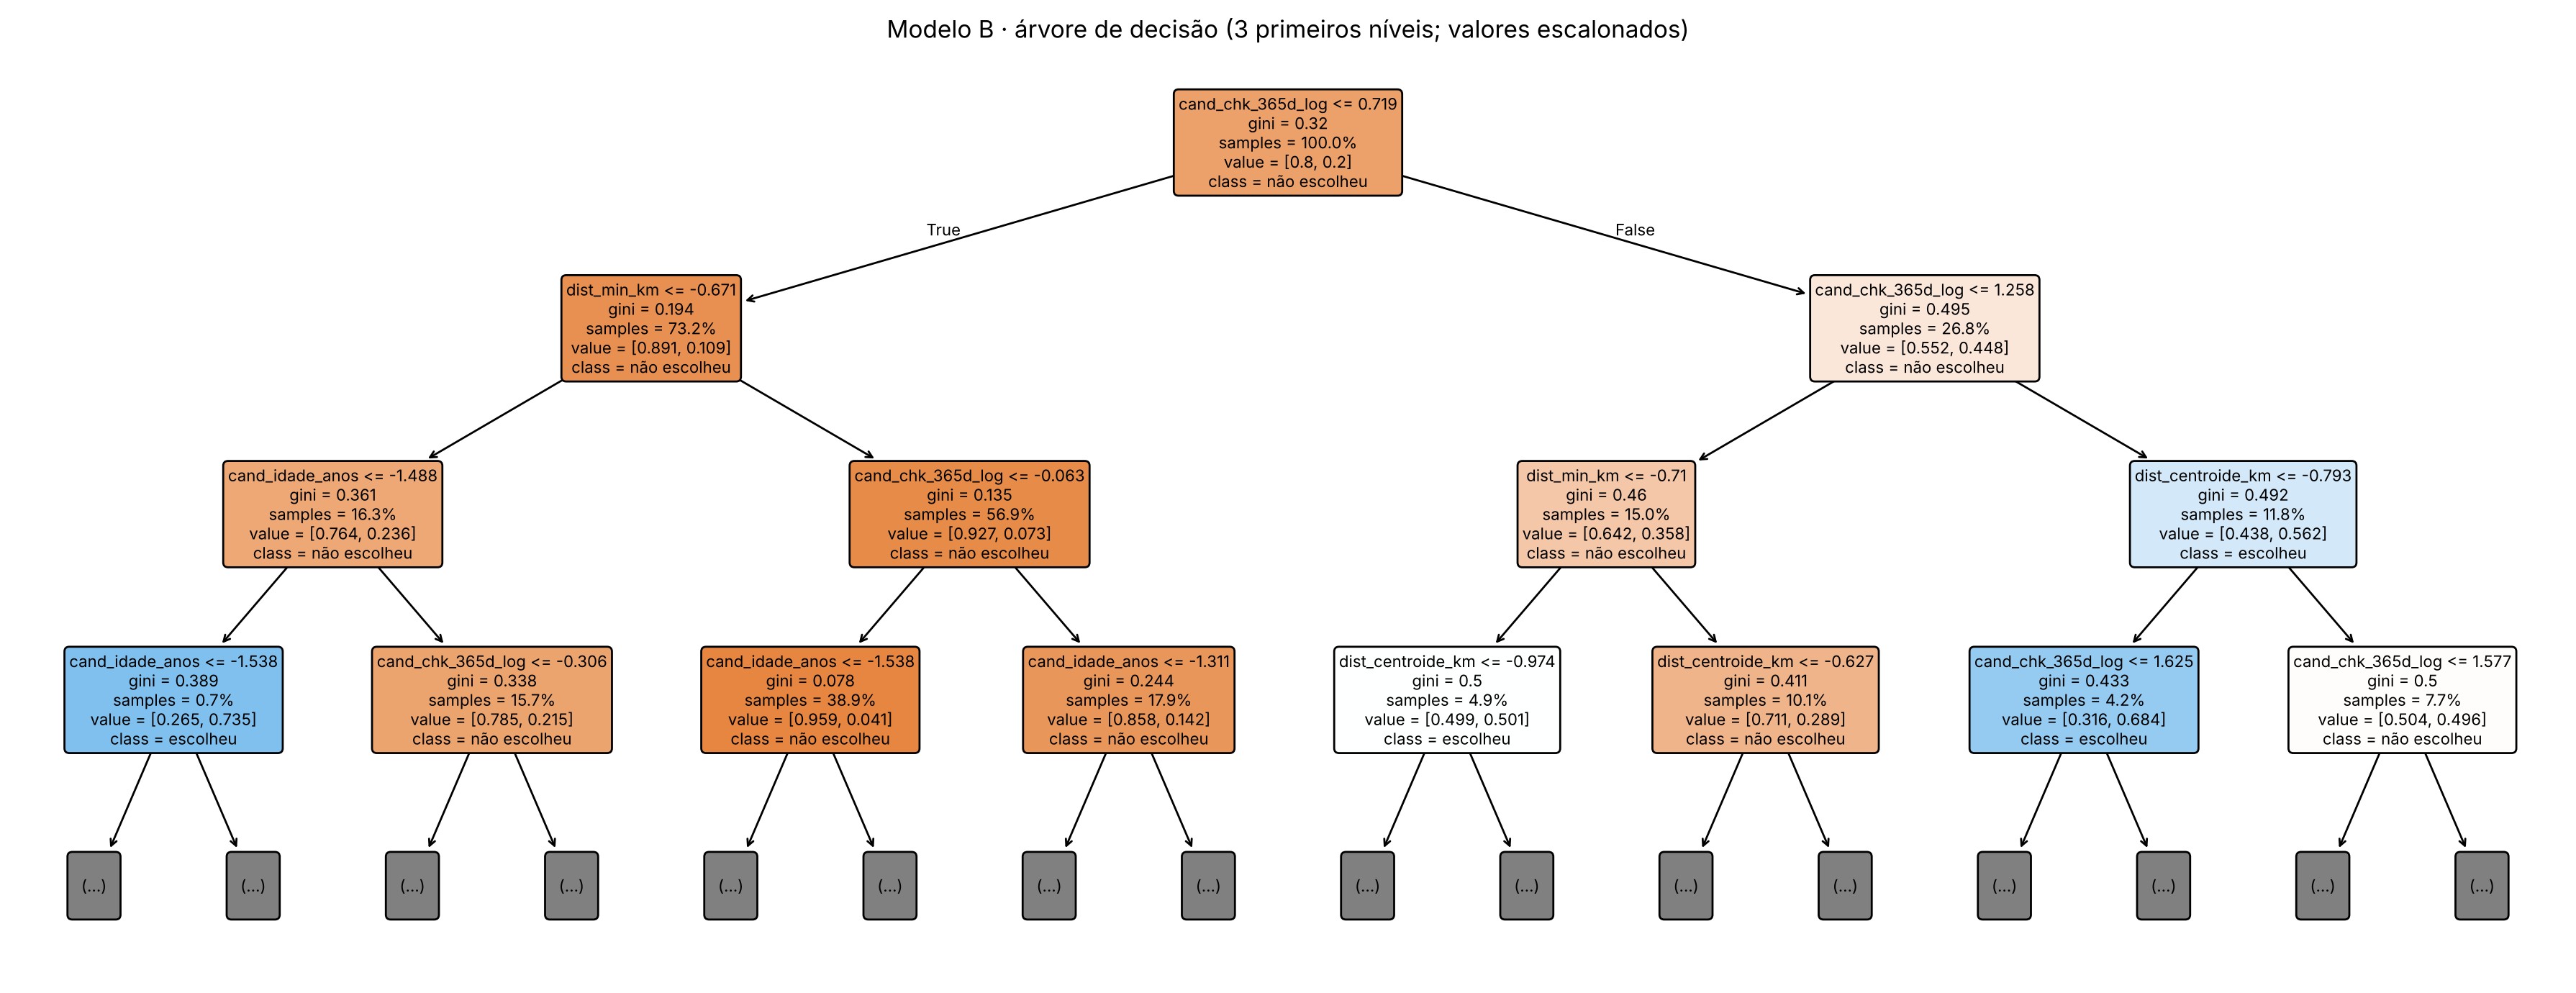

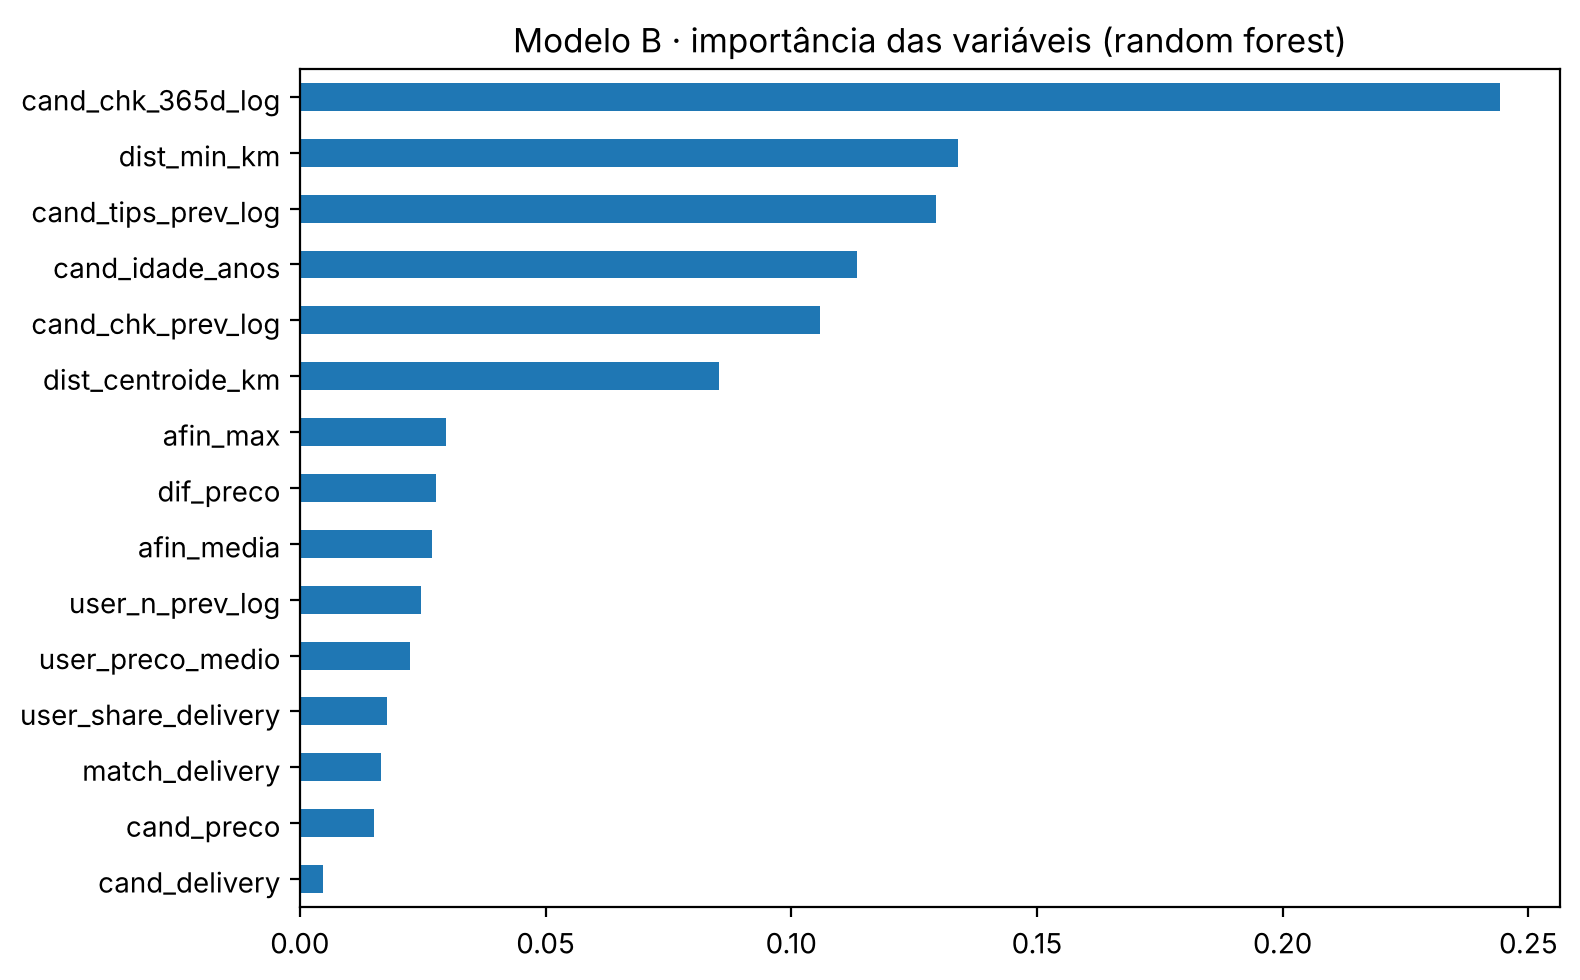

In [22]:
arvB = modelosB["Árvore de decisão"]
nomes_B = [n.replace("missingindicator_", "ausente_") for n in arvB.named_steps["imp"].get_feature_names_out(FEATS_B)]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvB.named_steps["clf"], max_depth=3, feature_names=nomes_B, class_names=["não escolheu", "escolheu"],
          filled=True, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Modelo B · árvore de decisão (3 primeiros níveis; valores escalonados)")
plt.tight_layout(); plt.savefig(SAIDA / "B_arvore.png", dpi=110); plt.show()

pd.Series(modelosB["Random forest"].named_steps["clf"].feature_importances_, index=nomes_B).sort_values().tail(15) \
  .plot.barh(figsize=(8, 5), title="Modelo B · importância das variáveis (random forest)")
plt.tight_layout(); plt.savefig(SAIDA / "B_importancias.png", dpi=120); plt.show()

## 6. Decisão (CRISP-DM)
A célula escreve a conclusão a partir dos números, para continuar correta se a base mudar.

In [23]:
def linha_txt(nome, r):
    return (f"  {nome:38s} acertos {r['Acertos (% do total)']:5.1f}% | FP {r['Falso positivo (% do total)']:5.1f}% | "
            f"FN {r['Falso negativo (% do total)']:5.1f}% | precisão {r['Precisão']:5.1f}% | AUC {r['AUC']:.3f}")

print("MODELO A · aprovação do restaurante")
for n in [MELHOR_A, "Popularidade (check-ins)", "Chute: todos aprovados"]:
    print(linha_txt(n, selA.loc[n]))
print("\nMODELO B · escolha do consumidor")
for n in [MELHOR_B, "Popularidade (check-ins até a data)", "Mais perto (distância)", "Chute: recomenda tudo"]:
    print(linha_txt(n, resB.loc[n]))

print("\nMODELO B · ranking (o escolhido fica em 1º entre 5?)")
for n in [MELHOR_B, "Popularidade (check-ins até a data)", "Mais perto (distância)", "Chute: recomenda tudo"]:
    print(f"  {n:38s} HitRate@1 {rankB.loc[n, 'HitRate@1 (%)']:5.1f}% | MRR {rankB.loc[n, 'MRR']:.3f}")

okA = selA.loc[MELHOR_A, "AUC"] > selA.loc["Popularidade (check-ins)", "AUC"]
okB = (resB.loc[MELHOR_B, "AUC"] > max(resB.loc["Popularidade (check-ins até a data)", "AUC"], resB.loc["Mais perto (distância)", "AUC"])
       and rankB.loc[MELHOR_B, "MRR"] > max(rankB.loc["Popularidade (check-ins até a data)", "MRR"], rankB.loc["Mais perto (distância)", "MRR"]))
print("\nDecisão:", "APROVAR os dois modelos para a Fase 5" if okA and okB else "rever a Fase 3 no modelo que não supera os baselines")

MODELO A · aprovação do restaurante
  Random forest                          acertos  74.3% | FP   8.0% | FN  17.7% | precisão  78.3% | AUC 0.821
  Popularidade (check-ins)               acertos  52.9% | FP  33.4% | FN  13.7% | precisão  49.6% | AUC 0.588
  Chute: todos aprovados                 acertos  46.5% | FP  53.5% | FN   0.0% | precisão  46.5% | AUC 0.500

MODELO B · escolha do consumidor
  Gradient boosting                      acertos  84.9% | FP   2.3% | FN  12.9% | precisão  76.0% | AUC 0.864
  Popularidade (check-ins até a data)    acertos  79.2% | FP   6.5% | FN  14.3% | precisão  46.7% | AUC 0.633
  Mais perto (distância)                 acertos  77.6% | FP   6.8% | FN  15.6% | precisão  39.3% | AUC 0.679
  Chute: recomenda tudo                  acertos  20.0% | FP  80.0% | FN   0.0% | precisão  20.0% | AUC 0.500

MODELO B · ranking (o escolhido fica em 1º entre 5?)
  Gradient boosting                      HitRate@1  67.5% | MRR 0.813
  Popularidade (check-ins até a data

## 7. Uso: top 5 a partir do questionário

O usuário responde à árvore do app: **modo** (pedir ou sair), **bairro**, **culinárias**, **teto de preço** e **raio**.
A regra está em `src/concierge/recomendador.py`, o mesmo arquivo que o app importa:

1. **Filtros de negócio:** aberto, faz delivery (pedir) ou aceita reserva (sair), culinária escolhida para hoje, preço
   até o teto e raio máximo.
2. **Guarda de qualidade (contra o falso positivo):** restaurante com 20+ avaliações precisa ter nota atual ≥ 4;
   restaurante com menos de 20 passa só se o **modelo A** estimar aprovação ≥ limiar de A. A probabilidade de A usada
   aqui é **fora da amostra** (validação cruzada no treino), para não favorecer os restaurantes que o modelo já viu.
3. **Modelo B (gosto):** as respostas preenchem o perfil como se ele tivesse 3 dicas (protocolo do questionário
   simulado do BU) e B ordena os candidatos. Só entra quem passa de um **piso de 50% do limiar F0,5 de B**. O limiar
   cheio foi escolhido para o protocolo 1 escolhido + 4 sorteados; aplicado depois da guarda de qualidade, ele deixava
   26% das respostas sem recomendação (notebook 04, seção 3.1). A seção 5.2 mostra o que o piso custa em precisão.
4. Se menos de 5 passarem, o top fica menor (BU: melhor 3 boas opções do que uma ruim).
5. **Vaga de descoberta:** se nenhum item estiver na metade de menor movimento da cidade, a última vaga vai para o
   restaurante de menor movimento com maior chance de escolha que passou na guarda (mitigação do viés para
   populares; o efeito é medido no notebook 04).

A variante **controle** usa os mesmos filtros e ordena por movimento e nota, sem modelo: é a ordenação atual dos apps
e o braço de controle do teste A/B (notebook 04).

> Mudança em relação à P2: antes o modelo A decidia sozinho para todos, e um restaurante com nota 3,5 podia entrar no
> top 5 com aprovação prevista de 63%. Agora a nota observada vale quando ela é confiável.

In [24]:
from concierge import recomendador as rec

modelo_A = modelos_padrao(PROF_A)[MELHOR_A].fit(rest.loc[idx_tr, cols_A], yA_tr)
LIM_A = limA_sel[MELHOR_A]
modelo_B, LIM_B = modelosB[MELHOR_B], limB[MELHOR_B]

# Aprovação prevista sem "decorar" o treino: fora da amostra no treino (5 folds) e previsão normal no teste
prob_ap = pd.Series(np.nan, index=rest.index)
prob_ap[idx_tr] = cross_val_predict(modelos_padrao(PROF_A)[MELHOR_A], rest.loc[idx_tr, cols_A], yA_tr,
                                    cv=CV, method="predict_proba")[:, 1]
prob_ap[idx_te] = modelo_A.predict_proba(rest.loc[idx_te, cols_A])[:, 1]

# Estado de cada restaurante "hoje" (fim da base): é o que o app teria na hora de recomendar
T_HOJE = int((FIM - EPOCA) // UM_S)
tab = R[["business_id", "nome", "stars", "review_count", "is_open", "lat", "lon", "preco", "delivery", "reservas",
         "culinarias"]].copy()
tab["prob_aprovacao"] = prob_ap.to_numpy()
tab["cand_chk_prev_log"] = [np.log1p(antes(ck_ts.get(c), T_HOJE)) for c in range(len(R))]
tab["cand_chk_365d_log"] = [np.log1p(antes(ck_ts.get(c), T_HOJE) - antes(ck_ts.get(c), T_HOJE - 365 * 86400))
                            for c in range(len(R))]
tab["cand_tips_prev_log"] = [np.log1p(antes(tip_ts.get(c), T_HOJE)) for c in range(len(R))]
tab["cand_idade_anos"] = [(T_HOJE - primeira[c]) / ANO if np.isfinite(primeira[c]) else np.nan for c in range(len(R))]

art = {"modelo_A": modelo_A, "nome_A": MELHOR_A, "limiar_A": LIM_A, "atributos_A": cols_A,
       "modelo_B": modelo_B, "nome_B": MELHOR_B, "limiar_B": LIM_B, "atributos_B": FEATS_B,
       "culinarias": CULINARIAS, "data_base": str(FIM.date())}

# Checagem: o módulo do app calcula os mesmos atributos que linha() usou no treino
cul_teste = CULINARIAS[:2]
p = rec.perfil_questionario(cul_teste, 2, "pedir", "Center City")
decl = np.zeros(len(CULINARIAS))
for c in cul_teste: decl[cul_idx[c]] = 3 / len(cul_teste)
est = {"n": 3, "cont": decl, "lats": [p["lat"]] * 3, "lons": [p["lon"]] * 3, "preco_soma": 6.0,
       "deliv_soma": 3.0, "deliv_n": 3}
amostra = rng.choice(len(R), size=min(300, len(R)), replace=False)
ref = pd.DataFrame([linha(est, c, T_HOJE) for c in amostra])[FEATS_B].to_numpy(dtype=float)
mod = rec.atributos_par(p, tab.iloc[amostra])[FEATS_B].to_numpy(dtype=float)
assert np.allclose(ref, mod, equal_nan=True), "atributos do app diferentes dos do treino"
print("Checagem ok: o app calcula os mesmos atributos do treino.")
print(f"Guarda de qualidade: nota observada para {(tab['review_count'] >= rec.MIN_AVALIACOES).mean():.0%} dos "
      f"restaurantes; modelo A ({MELHOR_A}, limiar {LIM_A:.2f}) para o restante.\n")


def mostrar(**perfil):
    out = rec.recomendar(tab, art, **perfil)
    if out.empty:
        return "Nenhum restaurante passa nos filtros e na guarda de qualidade: aumente o raio, o teto de preço ou as culinárias."
    return out.drop(columns=["business_id"]).round(3)


print("Perfil: PEDIR em Center City, Japanese ou Thai, até $$")
mostrar(culinarias=["Japanese", "Thai"], faixa_preco=2, modo="pedir", bairro="Center City")

Checagem ok: o app calcula os mesmos atributos do treino.
Guarda de qualidade: nota observada para 67% dos restaurantes; modelo A (Random forest, limiar 0.53) para o restante.

Perfil: PEDIR em Center City, Japanese ou Thai, até $$


,nome,culinaria,preco,dist_km,stars,review_count,prob_aprovacao,prob_escolha,descoberta,por que
0,Terakawa Ramen,Japanese,2.0,0.965,4.5,1693,0.802,0.618,False,Japanese · $$ · 1.0 km · nota 4.5
1,Chubby Cattle,"Japanese, Bars",2.0,0.818,4.5,1128,0.862,0.499,False,Japanese · $$ · 0.8 km · nota 4.5
2,Matcha Cafe Maiko,"Japanese, Cafes",2.0,0.921,4.0,46,0.720,0.474,False,Japanese · $$ · 0.9 km · nota 4.0
3,Ninja Bao,"Japanese, Asian Fusion",2.0,0.116,4.5,49,0.783,0.441,False,Japanese · $$ · 0.1 km · nota 4.5
4,Hiro Ramen House,"Japanese, Soul Food",2.0,0.612,4.0,435,0.763,0.427,False,Japanese · $$ · 0.6 km · nota 4.0


In [25]:
print("Mesmo perfil na variante CONTROLE (ordenação atual dos apps, sem modelo)")
display(mostrar(culinarias=["Japanese", "Thai"], faixa_preco=2, modo="pedir", bairro="Center City", variante="controle"))

print("Perfil: SAIR em South Philly, Italian ou Seafood, até $$$")
mostrar(culinarias=["Italian", "Seafood"], faixa_preco=3, modo="sair", bairro="South Philly", raio_km=4)

Mesmo perfil na variante CONTROLE (ordenação atual dos apps, sem modelo)


,nome,culinaria,preco,dist_km,stars,review_count,prob_aprovacao,prob_escolha,descoberta,por que
0,Terakawa Ramen,Japanese,2.0,0.965,4.5,1693,0.802,NaN,False,entre os mais movimentados perto de você
1,Spice 28,"Thai, Asian Fusion",2.0,0.397,4.0,822,0.650,NaN,False,entre os mais movimentados perto de você
2,Penang,"Thai, Asian Fusion",2.0,0.802,3.5,1112,0.716,NaN,False,entre os mais movimentados perto de você
3,Chubby Cattle,"Japanese, Bars",2.0,0.818,4.5,1128,0.862,NaN,False,entre os mais movimentados perto de você
4,Yakitori Boy,"Japanese, Sushi Bars",2.0,0.780,3.5,748,0.520,NaN,False,entre os mais movimentados perto de você


Perfil: SAIR em South Philly, Italian ou Seafood, até $$$


,nome,culinaria,preco,dist_km,stars,review_count,prob_aprovacao,prob_escolha,descoberta,por que
0,Le Virtu,Italian,3.0,0.199,4.0,389,0.753,0.562,False,Italian · $$$ · 0.2 km · nota 4.0
1,Oyster House,"Seafood, Steakhouses",3.0,2.868,4.0,1407,0.764,0.437,False,Seafood · $$$ · 2.9 km · nota 4.0
2,Gran Caffe L'Aquila,"Italian, Coffee & Tea",2.0,2.978,4.5,1138,0.777,0.422,False,Italian · $$ · 3.0 km · nota 4.5
3,Barbuzzo,"Italian, Mediterranean",2.0,2.896,4.5,2893,0.726,0.394,False,Italian · $$ · 2.9 km · nota 4.5
4,Chubby Cattle,"Seafood, Bars",2.0,3.566,4.5,1128,0.862,0.382,False,Seafood · $$ · 3.6 km · nota 4.5


In [26]:
import joblib
import sklearn

art["sklearn"] = sklearn.__version__          # o app precisa da mesma versão para ler o modelo
joblib.dump(art, MODELOS / rec.ARQ_MODELOS, compress=3)
tab.to_parquet(MODELOS / rec.ARQ_RESTAURANTES, index=False)
for f in [MODELOS / rec.ARQ_MODELOS, MODELOS / rec.ARQ_RESTAURANTES]:
    mb = f.stat().st_size / 1e6
    print(f"{f.relative_to(RAIZ)}: {mb:.1f} MB" + ("  <- acima do limite de 100 MB do GitHub" if mb > 95 else ""))
print("\nFiguras e tabelas em", SAIDA.relative_to(RAIZ))
for f in sorted(SAIDA.iterdir()): print("  ", f.name)

models/concierge_yelp.joblib: 2.9 MB
models/restaurantes.parquet: 0.5 MB

Figuras e tabelas em reports/03a_yelp
   01_bases.png
   A_arvore.png
   A_composicao_erros.png
   A_curva_arvore.png
   A_importancias.png
   A_matrizes_confusao.png
   A_metricas_teste.csv
   A_por_n_avaliacoes.csv
   B_arvore.png
   B_composicao_erros.png
   B_importancias.png
   B_limiar_sensibilidade.csv
   B_matrizes_confusao.png
   B_metricas_teste.csv
   B_ranking_teste.csv
   DU_hipotese_real.csv


## 8. Limites e próximos passos
- **Sem `review.json` aqui:** o modelo A prevê a aprovação **média** do restaurante, não a de cada pessoa; a
  personalização fica no modelo B. O `03b_modeling_reviews.ipynb` usa a nota individual e as duas versões podem ser
  comparadas.
- **Dica ≠ gostou:** a dica mostra que a pessoa foi, não que gostou (embora a maioria das dicas seja positiva). Por isso
  a guarda de qualidade vem antes do B.
- **Negativos sorteados:** "não deixou dica" não quer dizer "não gostaria", e os negativos vêm de toda a cidade, o que
  facilita o papel da distância. Os percentuais de B comparam modelos no mesmo protocolo; o CTR real só sai do teste A/B
  do piloto (notebook 04).
- **Snapshot no modelo A:** `stars` e as contagens de check-in e dicas são da mesma fotografia; no Brasil o cadastro dos
  parceiros e o histórico próprio substituem essas colunas. O número que vale para o app é o da faixa com poucas
  avaliações (seção 4.1).
- **Responsible AI:** sem atributos pessoais (gênero, idade, raça); a localização é aproximada (bairro e raio), e cada
  recomendação vem com o motivo. A cobertura do top 5 por porte de restaurante e por bairro é medida no notebook 04.